**2. Advanced NLP & Sentiment Profiling**  
Objective: Decode the emotional valence of contestant-specific discourse.
Pipeline:
- Sentiment Engines: Implement a tiered model approach:
    - VADER: For quick, rule-based valence.
    - Twitter-RoBERTa: For contextual sentiment.
    - Detoxify: To quantify hostility/insult levels.
    - Calculate episode and overall Sentiment and sentiment dispersion (standard deviation across comment-level scores).
    - Next: annotate episode trends with villa events; before/after comparisons remain future work.

**Past**  
I have attempted to fine-tune models, but they didn't work so well on our corpus.

## Data

In [116]:
from pathlib import Path

import duckdb
import pandas as pd

project_root = (
    Path.cwd().parent
    if Path.cwd().name == "notebooks"
    else Path.cwd()
)
db_path = project_root / "data" / "love_island_reddit.duckdb"

if not db_path.is_file():
    raise FileNotFoundError(db_path)

with duckdb.connect(str(db_path)) as con:
    sentiment_windows = con.execute("""
        SELECT *
        FROM islander_sentiment_windows
        ORDER BY episode, target_islander, comment_id, mention_start
    """).df()

print(f"Windows: {len(sentiment_windows):,}")
print(f"Islanders: {sentiment_windows['target_islander'].nunique()}")
print(f"Episodes: {sentiment_windows['episode'].nunique()}")

pd.set_option("display.max_colwidth", 200)

sentiment_windows[
    ["comment_id", "target_islander", "episode", "window_text", "model_text"]
].head(10)

Windows: 244,397
Islanders: 34
Episodes: 35


,comment_id,target_islander,episode,window_text,model_text
0,opf95vq,Aniya Harvey,1,i predict aniya & kc trinity & bryce melanie & sincere kenzie & zach beatriz & sean,i predict person & person person & person person & person person & person person & person
1,opfauab,Aniya Harvey,1,I love how excited kenzie and aniya are,I love how excited person and person are
2,opfb0qu,Aniya Harvey,1,I love aniyah and kenzie energy!!,I love person and person energy!!
3,opfb688,Aniya Harvey,1,Aniya is stunning 😍,person is stunning 😍
4,opfb9yg,Aniya Harvey,1,I am 24 why do I look like a child next to kenzie and aniya. I always look so young compared to love island people 😭,I am 24 why do I look like a child next to person and person. I always look so young compared to love island people 😭
5,opfbdpn,Aniya Harvey,1,Already going to be sad if Aniya leaves,Already going to be sad if person leaves
6,opfbj08,Aniya Harvey,1,ok now kenzie and aniya with all that screaming,ok now person and person with all that screaming
7,opfbmw0,Aniya Harvey,1,"Aniya's promo picture did her dirty, she is so pretty","person's promo picture did her dirty, she is so pretty"
8,opfbxsz,Aniya Harvey,1,So Aniya cannot count,So person cannot count
9,opfc60j,Aniya Harvey,1,"I adore Aniyah already!! She is adorable, charismatic, and seems so fun!! And Kenzie is so cringe in","I adore person already!! She is adorable, charismatic, and seems so fun!! And person is so cringe in"


## Sentiment Engines

### VADER
If want to rerun, set `FORCE_RERUN = True`.

In [117]:
# %pip install vaderSentiment tqdm

In [118]:
with duckdb.connect(str(db_path)) as con:
    sentiment_windows = con.execute("""
        SELECT *
        FROM islander_sentiment_windows
        ORDER BY episode, target_islander, comment_id, mention_start
    """).df()

In [119]:
from importlib.metadata import version

import duckdb
import pandas as pd
from tqdm.auto import tqdm
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

FORCE_RERUN = False
vader_version = version("vaderSentiment")

inputs = sentiment_windows[
    ["window_id", "comment_id", "target_islander", "episode", "model_text"]
].copy().reset_index(drop=True)

assert inputs["window_id"].is_unique
assert inputs["model_text"].notna().all()
assert inputs["model_text"].str.strip().ne("").all()

# Check for previously saved scores.
with duckdb.connect(str(db_path)) as con:
    cache_exists = con.execute("""
        SELECT COUNT(*)
        FROM information_schema.tables
        WHERE table_schema = 'main'
          AND table_name = 'vader_window_scores'
    """).fetchone()[0] > 0

    cached = (
        con.execute("SELECT * FROM main.vader_window_scores").df()
        if cache_exists else pd.DataFrame()
    )

score_columns = [
    "vader_neg", "vader_neu", "vader_pos", "vader_compound"
]
required_columns = [
    "window_id", "model_text", "vader_version", *score_columns
]

cache_valid = False

if not FORCE_RERUN and set(required_columns).issubset(cached.columns):
    current_text = inputs.set_index("window_id")["model_text"].sort_index()
    cached_text = cached.set_index("window_id")["model_text"].sort_index()

    cache_valid = (
        cached["window_id"].is_unique
        and current_text.equals(cached_text)
        and cached["vader_version"].eq(vader_version).all()
        and cached[score_columns].notna().all().all()
    )

if cache_valid:
    # Use current metadata with the saved scores.
    vader_results = inputs.merge(
        cached[["window_id", *score_columns]],
        on="window_id",
        how="left",
        validate="one_to_one",
    )
    print(f"Loaded {len(vader_results):,} cached VADER scores.")

else:
    analyzer = SentimentIntensityAnalyzer()

    scores = [
        analyzer.polarity_scores(text)
        for text in tqdm(inputs["model_text"], desc="Scoring with VADER")
    ]

    vader_results = pd.concat(
        [inputs, pd.DataFrame(scores).add_prefix("vader_")],
        axis=1,
    )
    print(f"Calculated {len(vader_results):,} VADER scores.")

vader_results["vader_version"] = vader_version

# Labels and summaries are inexpensive to rebuild from cached scores.
vader_results["vader_label"] = "neutral"
vader_results.loc[
    vader_results["vader_compound"] >= 0.05, "vader_label"
] = "positive"
vader_results.loc[
    vader_results["vader_compound"] <= -0.05, "vader_label"
] = "negative"

vader_by_episode = (
    vader_results
    .groupby(["episode", "target_islander"], as_index=False)
    .agg(
        num_windows=("window_id", "size"),
        mean_sentiment=("vader_compound", "mean"),
        sentiment_std=("vader_compound", "std"),
        positive_share=("vader_label", lambda x: x.eq("positive").mean()),
        neutral_share=("vader_label", lambda x: x.eq("neutral").mean()),
        negative_share=("vader_label", lambda x: x.eq("negative").mean()),
    )
)

# Persist both tables together.
with duckdb.connect(str(db_path)) as con:
    con.register("scores_export", vader_results)
    con.register("episode_export", vader_by_episode)
    con.execute("CREATE SCHEMA IF NOT EXISTS dashboard")

    con.execute("BEGIN TRANSACTION")
    try:
        con.execute("""
            CREATE OR REPLACE TABLE main.vader_window_scores AS
            SELECT * FROM scores_export
        """)
        con.execute("""
            CREATE OR REPLACE TABLE dashboard.vader_by_episode AS
            SELECT * FROM episode_export
        """)
        con.execute("COMMIT")
    except Exception:
        con.execute("ROLLBACK")
        raise

vader_by_episode.head(10)

Loaded 244,397 cached VADER scores.


,episode,target_islander,num_windows,mean_sentiment,sentiment_std,positive_share,neutral_share,negative_share
0,1,Aniya Harvey,232,0.331789,0.433791,0.650862,0.185345,0.163793
1,1,Beatriz Hatz,414,0.313950,0.438613,0.659420,0.173913,0.166667
2,1,Bryce Alakai Dettloff,419,0.154156,0.420631,0.522673,0.226730,0.250597
3,1,Kuman Chandler,466,0.092577,0.506069,0.469957,0.210300,0.319742
4,1,Mackenzie Annis,707,0.140501,0.477595,0.510608,0.200849,0.288543
5,1,Melanie Moreno,399,0.219211,0.448114,0.548872,0.255639,0.195489
6,1,Sean Reifel,317,0.151891,0.471218,0.507886,0.223975,0.268139
7,1,Sincere Rhea,370,0.253409,0.433135,0.578378,0.259459,0.162162
8,1,Trinity Tatum,349,0.212423,0.462396,0.555874,0.226361,0.217765
9,1,Zacharias Georgiou,460,0.173935,0.467543,0.545652,0.182609,0.271739


### Twitter-RoBERTa

In [120]:
# %pip install torch transformers tqdm

In [121]:
import hashlib
import json
from importlib.metadata import version

import duckdb
import numpy as np
import pandas as pd
import torch
from tqdm.auto import tqdm
from transformers import AutoTokenizer, AutoModelForSequenceClassification

MODEL_ID = "cardiffnlp/twitter-roberta-base-sentiment-latest"
FORCE_RERUN = False
BATCH_SIZE = 32
MAX_LENGTH = 512

# Increment this if you deliberately change preprocessing.
PREPROCESS_VERSION = 1

inputs = sentiment_windows[
    ["window_id", "comment_id", "target_islander", "episode", "model_text"]
].copy().reset_index(drop=True)

assert not inputs.empty
assert inputs["window_id"].is_unique
assert inputs["model_text"].notna().all()
assert inputs["model_text"].str.strip().ne("").all()

# Preprocessing recommended by the model authors.
def preprocess_roberta(text):
    return " ".join(
        "@user" if token.startswith("@") and len(token) > 1
        else "http" if token.startswith("http")
        else token
        for token in text.split()
    )

inputs["roberta_text"] = inputs["model_text"].map(preprocess_roberta)

cache_key = hashlib.sha256(json.dumps({
    "model": MODEL_ID,
    "max_length": MAX_LENGTH,
    "preprocessing": PREPROCESS_VERSION,
    "transformers_version": version("transformers"),
    "torch_version": version("torch"),
}, sort_keys=True).encode()).hexdigest()

prob_columns = ["roberta_neg", "roberta_neu", "roberta_pos"]

# Look for saved scores before loading the model.
with duckdb.connect(str(db_path)) as con:
    exists = con.execute("""
        SELECT COUNT(*)
        FROM information_schema.tables
        WHERE table_schema = 'main'
          AND table_name = 'roberta_window_scores'
    """).fetchone()[0] > 0

    cached = (
        con.execute("SELECT * FROM main.roberta_window_scores").df()
        if exists else pd.DataFrame()
    )

required = {
    "window_id", "roberta_text", "cache_key", "model_revision",
    *prob_columns,
}
cache_valid = False

if not FORCE_RERUN and required.issubset(cached.columns):
    current_text = inputs.set_index("window_id")["roberta_text"].sort_index()
    cached_text = cached.set_index("window_id")["roberta_text"].sort_index()

    cache_valid = (
        cached["window_id"].is_unique
        and current_text.equals(cached_text)
        and cached["cache_key"].eq(cache_key).all()
        and np.isfinite(cached[prob_columns].to_numpy()).all()
        and cached[prob_columns].ge(0).all().all()
        and cached[prob_columns].le(1).all().all()
        and np.allclose(cached[prob_columns].sum(axis=1), 1)
    )

if cache_valid:
    roberta_results = inputs.merge(
        cached[["window_id", *prob_columns, "model_revision"]],
        on="window_id",
        how="left",
        validate="one_to_one",
    )
    print(f"Loaded {len(roberta_results):,} cached RoBERTa scores.")

else:
    device = (
        "cuda" if torch.cuda.is_available()
        else "mps" if torch.backends.mps.is_available()
        else "cpu"
    )
    print(f"Scoring on: {device}")

    tokenizer = AutoTokenizer.from_pretrained(MODEL_ID)
    model = AutoModelForSequenceClassification.from_pretrained(MODEL_ID)
    model.to(device)
    model.eval()

    label_indices = {
        label.lower(): int(index)
        for index, label in model.config.id2label.items()
    }
    assert set(label_indices) == {"negative", "neutral", "positive"}

    # Score identical text once, while retaining every original window.
    unique_texts = inputs["roberta_text"].drop_duplicates().tolist()
    batches = []

    with torch.inference_mode():
        for start in tqdm(
            range(0, len(unique_texts), BATCH_SIZE),
            desc="Scoring with Twitter-RoBERTa",
        ):
            texts = unique_texts[start:start + BATCH_SIZE]

            encoded = tokenizer(
                texts,
                padding=True,
                truncation=True,
                max_length=MAX_LENGTH,
                return_tensors="pt",
            ).to(device)

            probabilities = torch.softmax(
                model(**encoded).logits, dim=-1
            ).cpu().numpy()

            batches.append(probabilities[:, [
                label_indices["negative"],
                label_indices["neutral"],
                label_indices["positive"],
            ]])

    text_scores = pd.DataFrame(
        np.concatenate(batches),
        columns=prob_columns,
    )
    text_scores["roberta_text"] = unique_texts

    roberta_results = inputs.merge(
        text_scores,
        on="roberta_text",
        how="left",
        validate="many_to_one",
    )
    roberta_results["model_revision"] = (
        getattr(model.config, "_commit_hash", None) or "unknown"
    )

    del model

# Continuous score for analysis: positive probability minus negative.
roberta_results["roberta_sentiment"] = (
    roberta_results["roberta_pos"] - roberta_results["roberta_neg"]
)

roberta_results["roberta_label"] = (
    roberta_results[prob_columns]
    .idxmax(axis=1)
    .map({
        "roberta_neg": "negative",
        "roberta_neu": "neutral",
        "roberta_pos": "positive",
    })
)

roberta_results["model_id"] = MODEL_ID
roberta_results["cache_key"] = cache_key

with duckdb.connect(str(db_path)) as con:
    con.register("roberta_export", roberta_results)
    con.execute("""
        CREATE OR REPLACE TABLE main.roberta_window_scores AS
        SELECT * FROM roberta_export
    """)

roberta_results[
    [
        "target_islander", "episode", "model_text",
        "roberta_neg", "roberta_neu", "roberta_pos",
        "roberta_sentiment", "roberta_label",
    ]
].head(10)

Loaded 244,397 cached RoBERTa scores.


,target_islander,episode,model_text,roberta_neg,roberta_neu,roberta_pos,roberta_sentiment,roberta_label
0,Aniya Harvey,1,i predict person & person person & person person & person person & person person & person,0.115330,0.806845,0.077826,-0.037504,neutral
1,Aniya Harvey,1,I love how excited person and person are,0.003643,0.014455,0.981903,0.978260,positive
2,Aniya Harvey,1,I love person and person energy!!,0.003411,0.014134,0.982455,0.979045,positive
3,Aniya Harvey,1,person is stunning 😍,0.014128,0.033776,0.952096,0.937968,positive
4,Aniya Harvey,1,I am 24 why do I look like a child next to person and person. I always look so young compared to love island people 😭,0.571360,0.364199,0.064441,-0.506918,negative
5,Aniya Harvey,1,Already going to be sad if person leaves,0.873036,0.115589,0.011375,-0.861661,negative
6,Aniya Harvey,1,ok now person and person with all that screaming,0.295485,0.623528,0.080987,-0.214498,neutral
7,Aniya Harvey,1,"person's promo picture did her dirty, she is so pretty",0.411333,0.280899,0.307768,-0.103565,negative
8,Aniya Harvey,1,So person cannot count,0.287620,0.670281,0.042099,-0.245522,neutral
9,Aniya Harvey,1,"I adore person already!! She is adorable, charismatic, and seems so fun!! And person is so cringe in",0.007813,0.012636,0.979551,0.971739,positive


### Detoxify

In [122]:
# %pip install detoxify tqdm

In [123]:
import hashlib
import json
from importlib.metadata import version

import duckdb
import numpy as np
import pandas as pd
import torch
from detoxify import Detoxify
from tqdm.auto import tqdm

DETOXIFY_MODEL = "unbiased"
FORCE_RERUN_DETOXIFY = False
DETOXIFY_BATCH_SIZE = 16

detoxify_inputs = sentiment_windows[
    ["window_id", "comment_id", "target_islander", "episode", "model_text"]
].copy().reset_index(drop=True)

assert not detoxify_inputs.empty
assert detoxify_inputs["window_id"].is_unique
assert detoxify_inputs["model_text"].notna().all()
assert detoxify_inputs["model_text"].str.strip().ne("").all()

categories = [
    "toxicity",
    "severe_toxicity",
    "obscene",
    "identity_attack",
    "insult",
    "threat",
    "sexual_explicit",
]
score_columns = [f"detoxify_{name}" for name in categories]

detoxify_cache_key = hashlib.sha256(
    json.dumps({
        "model": DETOXIFY_MODEL,
        "detoxify_version": version("detoxify"),
        "transformers_version": version("transformers"),
        "torch_version": version("torch"),
        "input": "model_text",
        "preprocessing_version": 1,
    }, sort_keys=True).encode()
).hexdigest()

# Check saved results before downloading/loading the model.
with duckdb.connect(str(db_path)) as con:
    cache_exists = con.execute("""
        SELECT COUNT(*)
        FROM information_schema.tables
        WHERE table_schema = 'main'
          AND table_name = 'detoxify_window_scores'
    """).fetchone()[0] > 0

    cached = (
        con.execute("SELECT * FROM main.detoxify_window_scores").df()
        if cache_exists else pd.DataFrame()
    )

required_columns = {
    "window_id", "model_text", "detoxify_cache_key", *score_columns
}
cache_valid = False

if (
    not FORCE_RERUN_DETOXIFY
    and required_columns.issubset(cached.columns)
):
    current_text = (
        detoxify_inputs.set_index("window_id")["model_text"].sort_index()
    )
    cached_text = (
        cached.set_index("window_id")["model_text"].sort_index()
    )

    cache_valid = (
        cached["window_id"].is_unique
        and current_text.equals(cached_text)
        and cached["detoxify_cache_key"].eq(detoxify_cache_key).all()
        and np.isfinite(cached[score_columns].to_numpy()).all()
        and cached[score_columns].ge(0).all().all()
        and cached[score_columns].le(1).all().all()
    )

if cache_valid:
    detoxify_results = detoxify_inputs.merge(
        cached[["window_id", *score_columns]],
        on="window_id",
        how="left",
        validate="one_to_one",
    )
    print(f"Loaded {len(detoxify_results):,} cached Detoxify scores.")

else:
    device = (
        "cuda" if torch.cuda.is_available()
        else "mps" if torch.backends.mps.is_available()
        else "cpu"
    )
    print(f"Scoring on: {device}")

    detoxify_model = Detoxify(DETOXIFY_MODEL, device=device)
    detoxify_model.model.eval()

    # Score identical text once, preserving every original window.
    unique_texts = detoxify_inputs["model_text"].drop_duplicates().tolist()
    batches = []

    with torch.inference_mode():
        for start in tqdm(
            range(0, len(unique_texts), DETOXIFY_BATCH_SIZE),
            desc="Scoring with Detoxify",
        ):
            texts = unique_texts[start:start + DETOXIFY_BATCH_SIZE]
            predictions = detoxify_model.predict(texts)

            batch = pd.DataFrame(predictions)
            batch = batch[categories].add_prefix("detoxify_")
            batch["model_text"] = texts
            batches.append(batch)

    text_scores = pd.concat(batches, ignore_index=True)

    detoxify_results = detoxify_inputs.merge(
        text_scores,
        on="model_text",
        how="left",
        validate="many_to_one",
    )

    del detoxify_model

    if device == "mps":
        torch.mps.empty_cache()
    elif device == "cuda":
        torch.cuda.empty_cache()

detoxify_results["detoxify_model"] = DETOXIFY_MODEL
detoxify_results["detoxify_cache_key"] = detoxify_cache_key

assert len(detoxify_results) == len(detoxify_inputs)
assert np.isfinite(detoxify_results[score_columns].to_numpy()).all()

with duckdb.connect(str(db_path)) as con:
    con.register("detoxify_export", detoxify_results)
    con.execute("""
        CREATE OR REPLACE TABLE main.detoxify_window_scores AS
        SELECT * FROM detoxify_export
    """)

detoxify_results[
    [
        "target_islander",
        "episode",
        "model_text",
        "detoxify_toxicity",
        "detoxify_insult",
        "detoxify_obscene",
    ]
].head(10)

Loaded 244,397 cached Detoxify scores.


,target_islander,episode,model_text,detoxify_toxicity,detoxify_insult,detoxify_obscene
0,Aniya Harvey,1,i predict person & person person & person person & person person & person person & person,0.000435,0.000113,0.000020
1,Aniya Harvey,1,I love how excited person and person are,0.000468,0.000124,0.000022
2,Aniya Harvey,1,I love person and person energy!!,0.000415,0.000111,0.000024
3,Aniya Harvey,1,person is stunning 😍,0.001207,0.000381,0.000030
4,Aniya Harvey,1,I am 24 why do I look like a child next to person and person. I always look so young compared to love island people 😭,0.000750,0.000153,0.000043
5,Aniya Harvey,1,Already going to be sad if person leaves,0.004020,0.000356,0.000066
6,Aniya Harvey,1,ok now person and person with all that screaming,0.010399,0.001643,0.000076
7,Aniya Harvey,1,"person's promo picture did her dirty, she is so pretty",0.175608,0.097616,0.004036
8,Aniya Harvey,1,So person cannot count,0.000920,0.000221,0.000023
9,Aniya Harvey,1,"I adore person already!! She is adorable, charismatic, and seems so fun!! And person is so cringe in",0.000965,0.000249,0.000033


### Combine Scores

In [124]:
import numpy as np
import pandas as pd

# Verify coverage and input consistency before combining.
models = {
    "VADER": vader_results,
    "RoBERTa": roberta_results,
    "Detoxify": detoxify_results,
}

reference = vader_results.set_index("window_id").sort_index()
identity_columns = [
    "comment_id", "target_islander", "episode", "model_text"
]

for name, frame in models.items():
    assert frame["window_id"].is_unique, f"{name}: duplicate window IDs"

    candidate = frame.set_index("window_id").sort_index()
    assert reference.index.equals(candidate.index), (
        f"{name}: windows differ. Load/score the same input dataset first."
    )

    for column in identity_columns:
        assert reference[column].eq(candidate[column]).all(), (
            f"{name}: mismatched {column}"
        )

toxicity_columns = [
    "detoxify_toxicity",
    "detoxify_severe_toxicity",
    "detoxify_obscene",
    "detoxify_identity_attack",
    "detoxify_insult",
    "detoxify_threat",
    "detoxify_sexual_explicit",
]

combined_scores = (
    vader_results[
        [
            "window_id", *identity_columns,
            "vader_compound", "vader_label",
        ]
    ]
    .merge(
        roberta_results[
            [
                "window_id",
                "roberta_neg", "roberta_neu", "roberta_pos",
                "roberta_sentiment", "roberta_label",
            ]
        ],
        on="window_id",
        validate="one_to_one",
    )
    .merge(
        detoxify_results[["window_id", *toxicity_columns]],
        on="window_id",
        validate="one_to_one",
    )
)

numeric_columns = [
    "vader_compound", "roberta_sentiment", *toxicity_columns
]
assert np.isfinite(combined_scores[numeric_columns].to_numpy()).all()

combined_scores["sentiment_agreement"] = (
    combined_scores["vader_label"] == combined_scores["roberta_label"]
)

combined_scores["opposite_sentiment"] = (
    (
        combined_scores["vader_label"].eq("positive")
        & combined_scores["roberta_label"].eq("negative")
    )
    | (
        combined_scores["vader_label"].eq("negative")
        & combined_scores["roberta_label"].eq("positive")
    )
)

print(f"Combined {len(combined_scores):,} windows.")
combined_scores.head()

Combined 244,397 windows.


,window_id,comment_id,target_islander,episode,model_text,vader_compound,vader_label,roberta_neg,roberta_neu,roberta_pos,...,roberta_label,detoxify_toxicity,detoxify_severe_toxicity,detoxify_obscene,detoxify_identity_attack,detoxify_insult,detoxify_threat,detoxify_sexual_explicit,sentiment_agreement,opposite_sentiment
0,4056babe51ceaf9dd6df84fd295f03adebb964b1a355cefa928587aafb067362,opf95vq,Aniya Harvey,1,i predict person & person person & person person & person person & person person & person,0.0000,neutral,0.115330,0.806845,0.077826,...,neutral,0.000435,0.000001,0.000020,0.000077,0.000113,0.000016,0.000015,True,False
1,289017a2f6bd5ef1aa4d347754afa4b2ca8e8918f15ec5c8290ed17dc16ced33,opfauab,Aniya Harvey,1,I love how excited person and person are,0.7650,positive,0.003643,0.014455,0.981903,...,positive,0.000468,0.000001,0.000022,0.000084,0.000124,0.000018,0.000014,True,False
2,bf093b45ae99a4a84ed633e039687faf7520f688329f223d2bddb0c81444e7ea,opfb0qu,Aniya Harvey,1,I love person and person energy!!,0.7835,positive,0.003411,0.014134,0.982455,...,positive,0.000415,0.000002,0.000024,0.000070,0.000111,0.000018,0.000017,True,False
3,c2134070a2bca3c51d73c02d6d6c5157e0fefca18b4904b3e2658d3ed25988a1,opfb688,Aniya Harvey,1,person is stunning 😍,0.6808,positive,0.014128,0.033776,0.952096,...,positive,0.001207,0.000001,0.000030,0.000083,0.000381,0.000022,0.000014,True,False
4,e8f7a0932b09174195ec5f64332a281d2333c83b3cef3011f2fdf3451b746ccb,opfb9yg,Aniya Harvey,1,I am 24 why do I look like a child next to person and person. I always look so young compared to love island people 😭,0.5574,positive,0.571360,0.364199,0.064441,...,negative,0.000750,0.000002,0.000043,0.000158,0.000153,0.000021,0.000021,False,True


### Comment-level scores
Average windows within each comment–islander pair before calculating comment-weighted summaries.


In [125]:
# Each comment should have one episode.
assert (
    combined_scores.groupby("comment_id")["episode"].nunique() <= 1
).all()

comment_aggregations = {
    "episode": ("episode", "first"),
    "num_windows": ("window_id", "size"),
    "vader_sentiment": ("vader_compound", "mean"),
    "roberta_sentiment": ("roberta_sentiment", "mean"),
    "agreement_share": ("sentiment_agreement", "mean"),
    "opposite_share": ("opposite_sentiment", "mean"),
}

comment_aggregations.update({
    column: (column, "mean")
    for column in toxicity_columns
})

comment_islander_scores = (
    combined_scores
    .groupby(["comment_id", "target_islander"], as_index=False)
    .agg(**comment_aggregations)
)



### Correlation Between Sentiment Scores

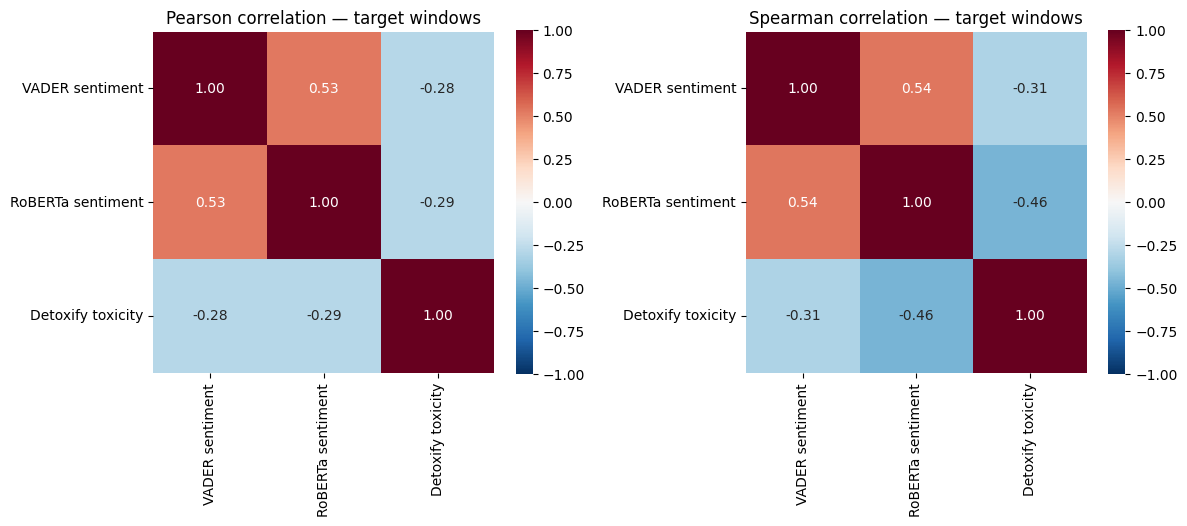

In [126]:
import matplotlib.pyplot as plt
import seaborn as sns

score_columns = {
    "vader_compound": "VADER sentiment",
    "roberta_sentiment": "RoBERTa sentiment",
    "detoxify_toxicity": "Detoxify toxicity",
}

correlation_data = combined_scores[list(score_columns)].rename(
    columns=score_columns
)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for ax, method in zip(axes, ["pearson", "spearman"]):
    sns.heatmap(
        correlation_data.corr(method=method),
        annot=True,
        fmt=".2f",
        cmap="RdBu_r",
        vmin=-1,
        vmax=1,
        center=0,
        square=True,
        ax=ax,
    )
    ax.set_title(f"{method.title()} correlation — target windows")

plt.tight_layout()
plt.show()

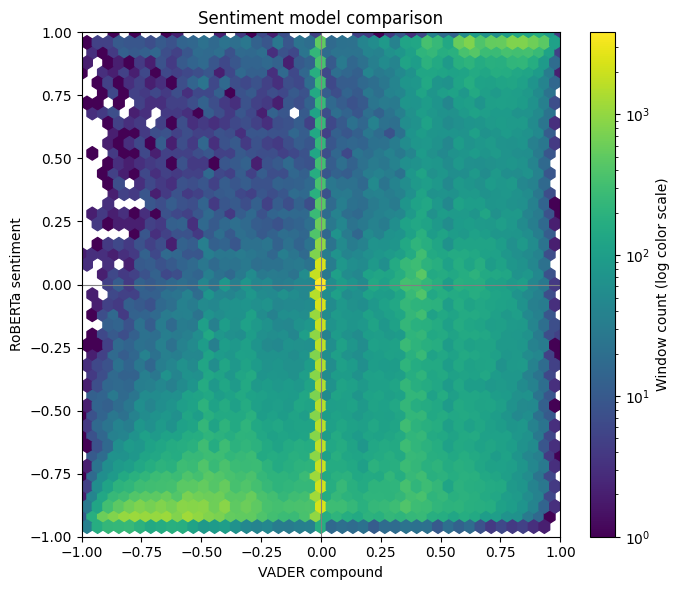

In [127]:
fig, ax = plt.subplots(figsize=(7, 6))

density = ax.hexbin(
    combined_scores["vader_compound"],
    combined_scores["roberta_sentiment"],
    gridsize=45,
    extent=(-1, 1, -1, 1),
    mincnt=1,
    bins="log",
    cmap="viridis",
)

ax.axhline(0, color="gray", linewidth=0.8)
ax.axvline(0, color="gray", linewidth=0.8)
ax.set(
    xlabel="VADER compound",
    ylabel="RoBERTa sentiment",
    title="Sentiment model comparison",
    xlim=(-1, 1),
    ylim=(-1, 1),
)
fig.colorbar(density, ax=ax, label="Window count (log color scale)")
plt.tight_layout()
plt.show()

In [128]:
sentiment_by_episode = (
    comment_islander_scores
    .groupby(["episode", "target_islander"], as_index=False)
    .agg(
        num_comments=("comment_id", "size"),
        num_windows=("num_windows", "sum"),
        vader_mean=("vader_sentiment", "mean"),
        vader_std=("vader_sentiment", "std"),
        roberta_mean=("roberta_sentiment", "mean"),
        roberta_std=("roberta_sentiment", "std"),
        toxicity_mean=("detoxify_toxicity", "mean"),
        insult_mean=("detoxify_insult", "mean"),
        agreement_share=("agreement_share", "mean"),
    )
    .sort_values(["target_islander", "episode"])
    .reset_index(drop=True)
)

sentiment_by_episode.head()

,episode,target_islander,num_comments,num_windows,vader_mean,vader_std,roberta_mean,roberta_std,toxicity_mean,insult_mean,agreement_share
0,16,Alannah Keyser,1,2,-0.096550,NaN,-0.094125,NaN,0.002342,0.000405,0.000000
1,17,Alannah Keyser,180,183,0.053342,0.414312,-0.390925,0.465519,0.085959,0.019504,0.474074
2,18,Alannah Keyser,276,279,0.058211,0.419182,-0.372984,0.457466,0.107893,0.049977,0.501812
3,19,Alannah Keyser,114,115,0.001274,0.384705,-0.442940,0.377489,0.101636,0.032198,0.429825
4,20,Alannah Keyser,247,252,0.142368,0.445880,-0.344867,0.443851,0.086347,0.027362,0.380567


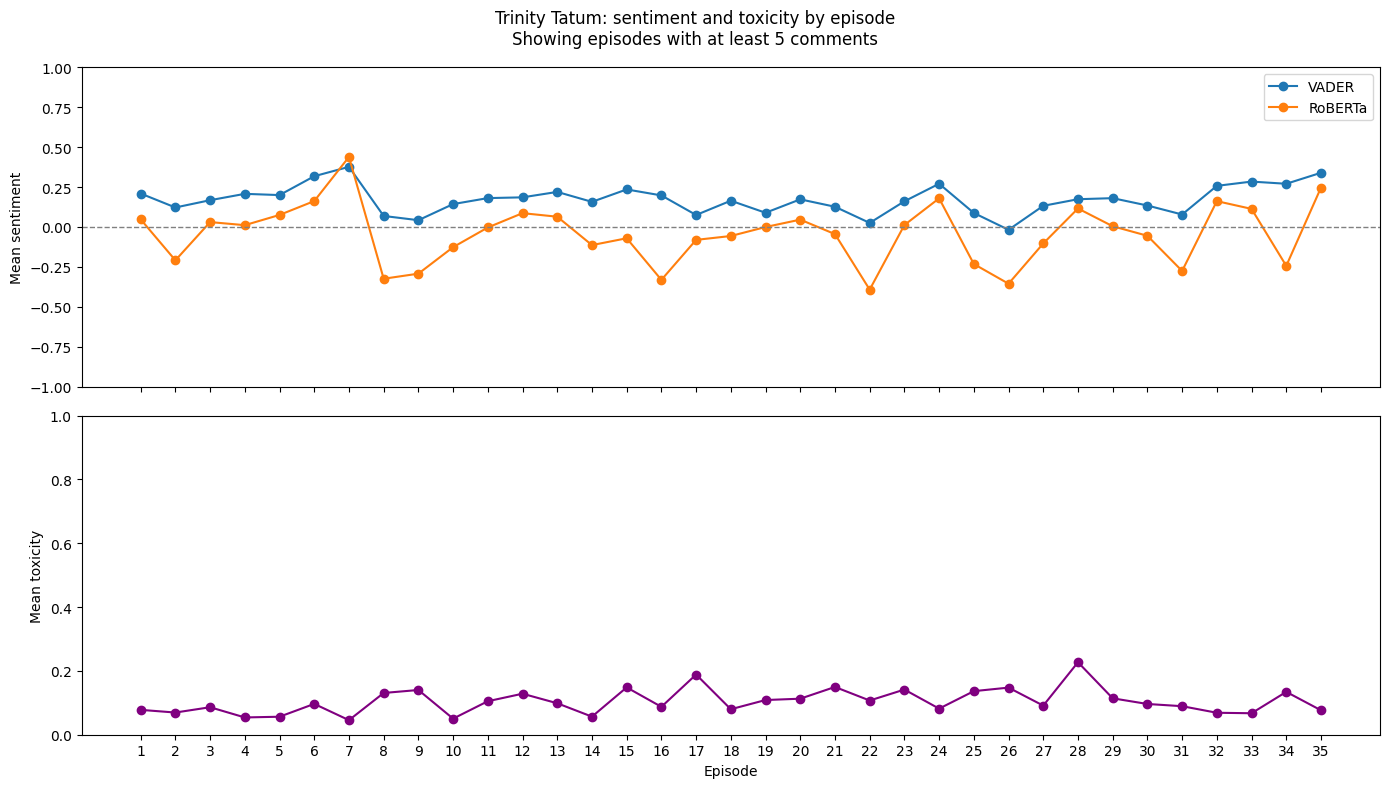

In [129]:
ISLANDER = "Trinity Tatum"

# A display filter, not a statistical significance threshold.
MIN_COMMENTS = 5

trend = (
    sentiment_by_episode
    .query("target_islander == @ISLANDER")
    .set_index("episode")
)

# Include missing episodes so the plot does not bridge gaps.
episodes = range(
    int(sentiment_by_episode["episode"].min()),
    int(sentiment_by_episode["episode"].max()) + 1,
)
trend = trend.reindex(episodes)

metric_columns = ["vader_mean", "roberta_mean", "toxicity_mean"]
trend.loc[
    trend["num_comments"].fillna(0) < MIN_COMMENTS,
    metric_columns,
] = float("nan")

fig, axes = plt.subplots(2, 1, figsize=(14, 8), sharex=True)

axes[0].plot(
    trend.index, trend["vader_mean"], marker="o", label="VADER"
)
axes[0].plot(
    trend.index, trend["roberta_mean"], marker="o", label="RoBERTa"
)
axes[0].axhline(0, color="gray", linestyle="--", linewidth=1)
axes[0].set(ylabel="Mean sentiment", ylim=(-1, 1))
axes[0].legend()

axes[1].plot(
    trend.index,
    trend["toxicity_mean"],
    marker="o",
    color="purple",
)
axes[1].set(
    xlabel="Episode",
    ylabel="Mean toxicity",
    ylim=(0, 1),
)
axes[1].set_xticks(list(episodes))

fig.suptitle(
    f"{ISLANDER}: sentiment and toxicity by episode\n"
    f"Showing episodes with at least {MIN_COMMENTS} comments"
)
plt.tight_layout()
plt.show()

### Overall Islander Sentiments

In [130]:
overall_aggregations = {
    "num_comments": ("comment_id", "size"),
    "num_windows": ("num_windows", "sum"),
    "num_episodes": ("episode", "nunique"),
    "vader_mean": ("vader_sentiment", "mean"),
    "vader_std": ("vader_sentiment", "std"),
    "roberta_mean": ("roberta_sentiment", "mean"),
    "roberta_std": ("roberta_sentiment", "std"),
    "agreement_share": ("agreement_share", "mean"),
    "opposite_share": ("opposite_share", "mean"),
}

overall_aggregations.update({
    f"{column}_mean": (column, "mean")
    for column in toxicity_columns
})

overall_islander_summary = (
    comment_islander_scores
    .groupby("target_islander", as_index=False)
    .agg(**overall_aggregations)
    .sort_values("num_comments", ascending=False)
    .reset_index(drop=True)
)

# Display rounded values without changing the stored precision.
overall_islander_summary[
    [
        "target_islander",
        "num_comments",
        "num_windows",
        "vader_mean",
        "roberta_mean",
        "detoxify_toxicity_mean",
        "detoxify_insult_mean",
        "agreement_share",
        "opposite_share",
    ]
].round(3)

,target_islander,num_comments,num_windows,vader_mean,roberta_mean,detoxify_toxicity_mean,detoxify_insult_mean,agreement_share,opposite_share
0,Melanie Moreno,23557,26572,0.044,-0.350,0.137,0.068,0.520,0.184
1,Sincere Rhea,23189,25434,0.002,-0.430,0.168,0.085,0.515,0.185
2,Mackenzie Annis,20219,22268,0.058,-0.330,0.134,0.060,0.508,0.171
3,Kuman Chandler,18048,20172,0.016,-0.372,0.170,0.088,0.530,0.171
4,Zacharias Georgiou,17351,18773,0.017,-0.413,0.160,0.077,0.508,0.175
5,Aniya Harvey,16793,18602,0.078,-0.250,0.126,0.059,0.546,0.173
6,Bryce Alakai Dettloff,13657,14757,0.119,-0.157,0.119,0.049,0.535,0.148
7,Kayda Bosse,12913,14139,0.063,-0.317,0.125,0.056,0.511,0.177
8,Trinity Tatum,11946,12969,0.165,-0.038,0.106,0.042,0.563,0.140
9,Corbin Mims,10266,11149,0.049,-0.336,0.169,0.081,0.513,0.169


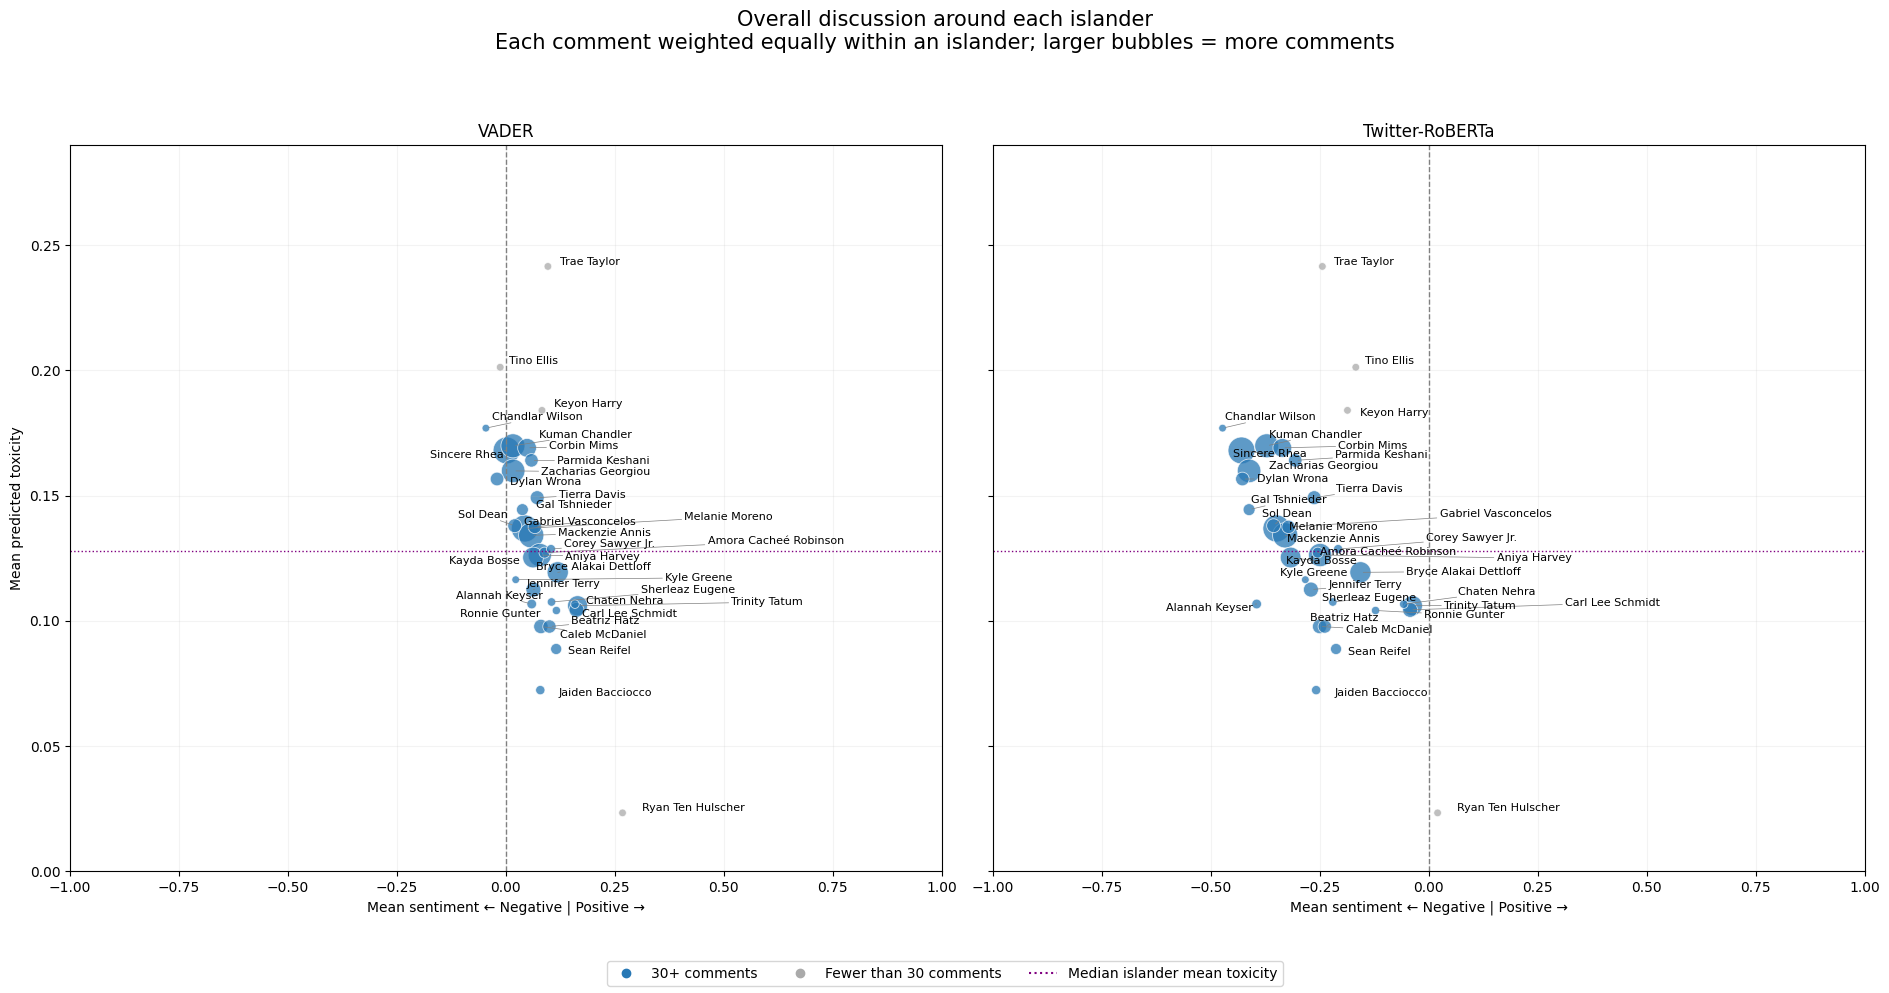

In [131]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from adjustText import adjust_text

plot_df = overall_islander_summary.copy()

# Bubble area reflects comment volume.
sizes = 30 + 350 * (
    plot_df["num_comments"] / plot_df["num_comments"].max()
)

# Flag small samples without hiding them.
small_sample = plot_df["num_comments"] < 30
colors = small_sample.map({True: "#aaaaaa", False: "#2878B5"})

# Relative reference line, not a toxic/non-toxic threshold.
toxicity_median = plot_df["detoxify_toxicity_mean"].median()

fig, axes = plt.subplots(
    1, 2, figsize=(19, 10), sharex=True, sharey=True
)

for ax, score, title in zip(
    axes,
    ["vader_mean", "roberta_mean"],
    ["VADER", "Twitter-RoBERTa"],
):
    ax.scatter(
        plot_df[score],
        plot_df["detoxify_toxicity_mean"],
        s=sizes,
        c=colors,
        alpha=0.75,
        edgecolors="white",
        linewidths=0.6,
    )

    texts = [
        ax.text(
            row[score],
            row["detoxify_toxicity_mean"],
            row["target_islander"],
            fontsize=8,
        )
        for _, row in plot_df.iterrows()
    ]

    ax.axvline(0, color="gray", linestyle="--", linewidth=1)
    ax.axhline(
        toxicity_median,
        color="purple",
        linestyle=":",
        linewidth=1,
    )

    ax.set(
        title=title,
        xlabel="Mean sentiment ← Negative | Positive →",
        xlim=(-1, 1),
    )
    ax.grid(alpha=0.15)

    adjust_text(
        texts,
        ax=ax,
        arrowprops={"arrowstyle": "-", "color": "gray", "lw": 0.5},
    )

axes[0].set_ylabel("Mean predicted toxicity")
axes[0].set_ylim(
    0,
    max(0.1, plot_df["detoxify_toxicity_mean"].max() * 1.2),
)

legend = [
    Line2D(
        [0], [0], marker="o", linestyle="",
        color="#2878B5", label="30+ comments",
    ),
    Line2D(
        [0], [0], marker="o", linestyle="",
        color="#aaaaaa", label="Fewer than 30 comments",
    ),
    Line2D(
        [0], [0], color="purple", linestyle=":",
        label="Median islander mean toxicity",
    ),
]

fig.legend(handles=legend, loc="lower center", ncol=3)
fig.suptitle(
    "Overall discussion around each islander\n"
    "Each comment weighted equally within an islander; "
    "larger bubbles = more comments",
    fontsize=15,
)
plt.tight_layout(rect=[0, 0.06, 1, 0.94])
plt.show()

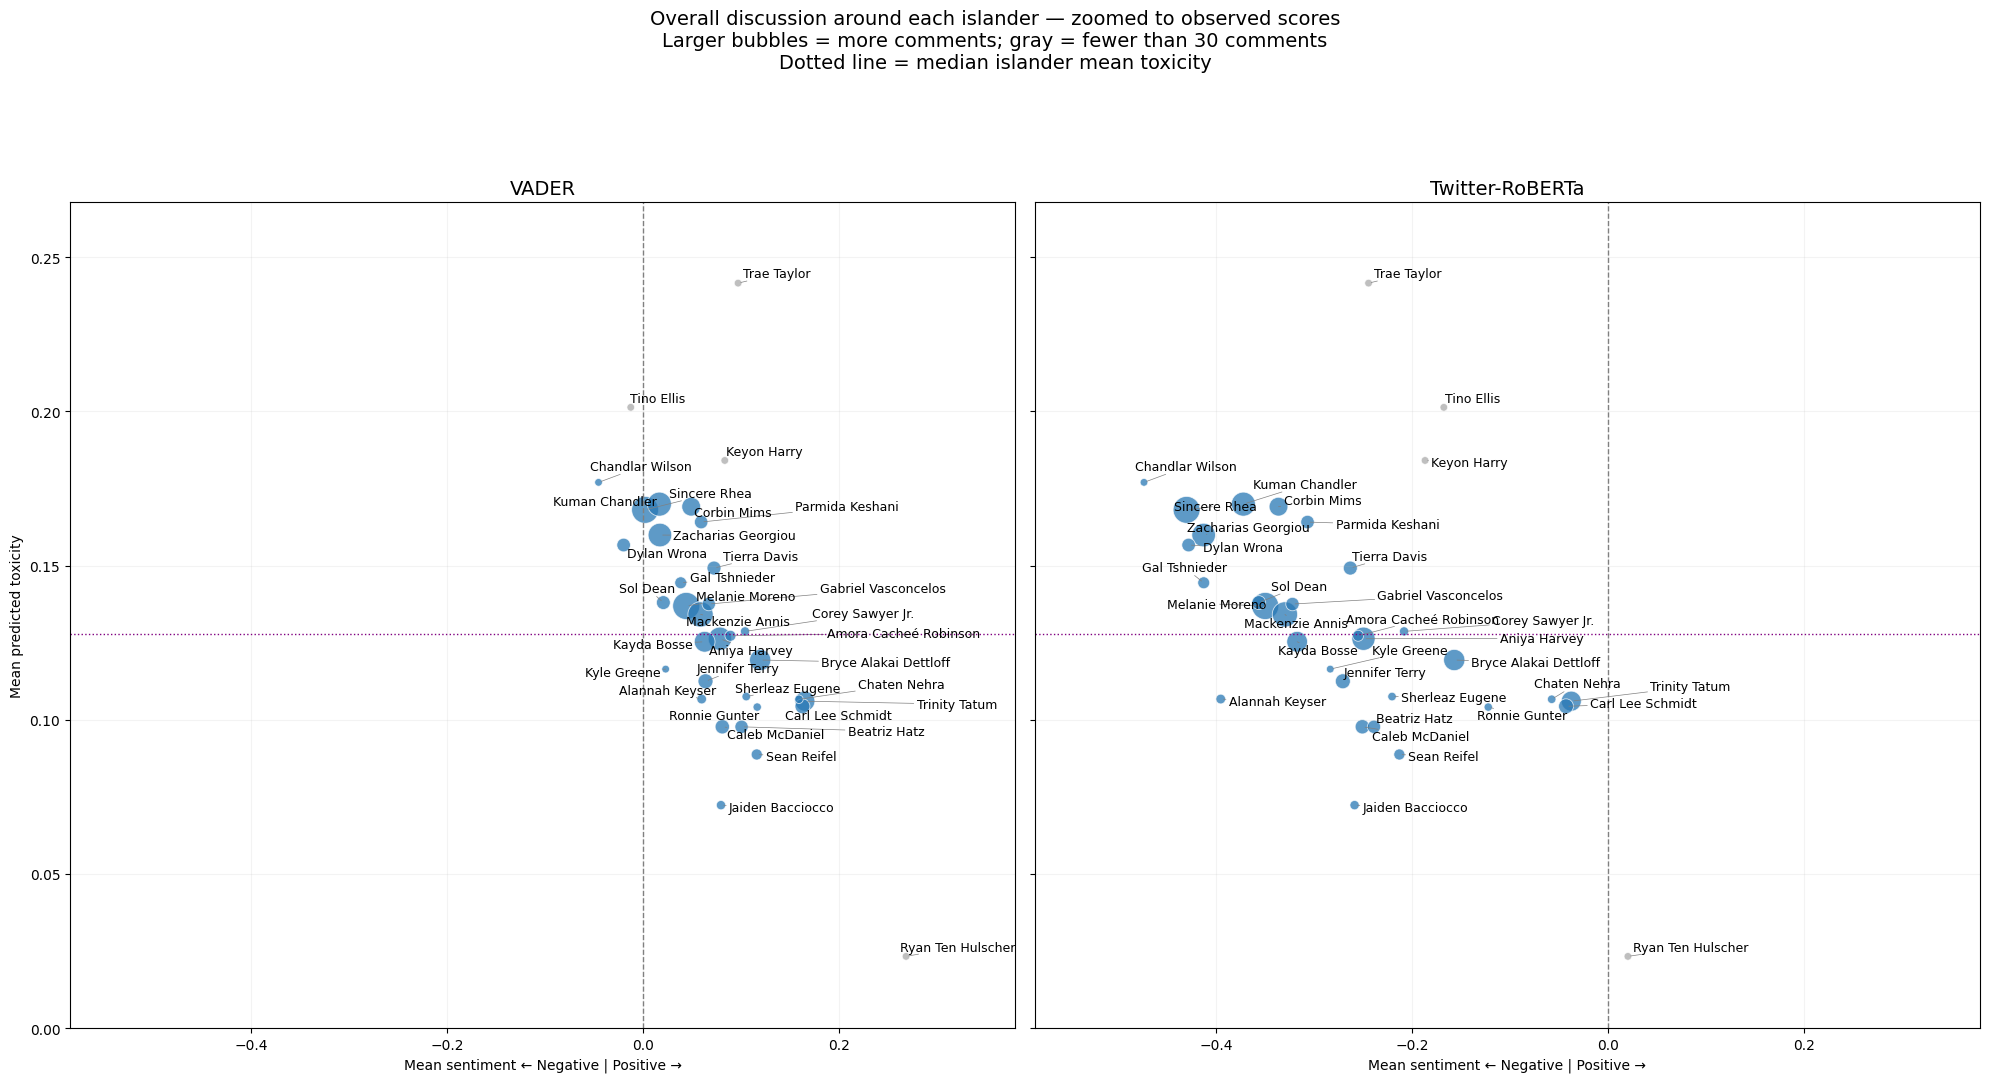

In [132]:
import matplotlib.pyplot as plt
from adjustText import adjust_text

plot_df = overall_islander_summary.copy()

# Shared sentiment limits across BOTH models.
sentiment_values = plot_df[["vader_mean", "roberta_mean"]]
xmin = sentiment_values.min().min()
xmax = sentiment_values.max().max()
xpad = max((xmax - xmin) * 0.15, 0.02)

ymin = plot_df["detoxify_toxicity_mean"].min()
ymax = plot_df["detoxify_toxicity_mean"].max()
ypad = max((ymax - ymin) * 0.12, 0.01)

sizes = 30 + 350 * (
    plot_df["num_comments"] / plot_df["num_comments"].max()
)
colors = [
    "#aaaaaa" if count < 30 else "#2878B5"
    for count in plot_df["num_comments"]
]
toxicity_median = plot_df["detoxify_toxicity_mean"].median()

fig, axes = plt.subplots(
    1, 2, figsize=(20, 11), sharex=True, sharey=True
)

for ax, score, title in zip(
    axes,
    ["vader_mean", "roberta_mean"],
    ["VADER", "Twitter-RoBERTa"],
):
    # Set final limits BEFORE adjusting labels.
    ax.set_xlim(xmin - xpad, xmax + xpad)
    ax.set_ylim(max(0, ymin - ypad), min(1, ymax + ypad))

    ax.scatter(
        plot_df[score],
        plot_df["detoxify_toxicity_mean"],
        s=sizes,
        c=colors,
        alpha=0.75,
        edgecolors="white",
        linewidths=0.6,
    )

    ax.axvline(0, color="gray", linestyle="--", linewidth=1)
    ax.axhline(
        toxicity_median,
        color="purple",
        linestyle=":",
        linewidth=1,
    )
    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Mean sentiment ← Negative | Positive →")
    ax.grid(alpha=0.15)

axes[0].set_ylabel("Mean predicted toxicity")

fig.suptitle(
    "Overall discussion around each islander — zoomed to observed scores\n"
    "Larger bubbles = more comments; gray = fewer than 30 comments\n"
    "Dotted line = median islander mean toxicity",
    fontsize=14,
)
plt.tight_layout(rect=[0, 0, 1, 0.91])

# Place labels after the layout and axis limits are finalized.
for ax, score in zip(axes, ["vader_mean", "roberta_mean"]):
    texts = [
        ax.text(
            row[score],
            row["detoxify_toxicity_mean"],
            row["target_islander"],
            fontsize=9,
        )
        for _, row in plot_df.iterrows()
    ]

    adjust_text(
        texts,
        ax=ax,
        expand=(1.15, 1.3),
        arrowprops={
            "arrowstyle": "-",
            "color": "gray",
            "lw": 0.5,
        },
    )

plt.show()

### Sentiment dispersion

`vader_std` and `roberta_std` are sample standard deviations (`ddof=1`) across comment–islander mean scores. Higher values mean more varied sentiment; lower values mean more consistent sentiment. They do not establish polarization or indicate uncertainty in the mean. A group with one comment has undefined dispersion (NaN). Compare dispersion within each model because their score scales differ.

These differ from `vader_cast_sd` and `roberta_cast_sd`, which measure the spread of islander averages and are used for relative-sentiment z-scores. Both overall and per-episode exports retain the comment-level dispersion columns.


In [133]:
overall_islander_summary[
    ["target_islander", "num_comments", "vader_mean", "vader_std",
     "roberta_mean", "roberta_std"]
].sort_values("roberta_std", ascending=False).round(3)


,target_islander,num_comments,vader_mean,vader_std,roberta_mean,roberta_std
8,Trinity Tatum,11946,0.165,0.481,-0.038,0.647
11,Carl Lee Schmidt,5742,0.162,0.467,-0.043,0.632
33,Trae Taylor,17,0.097,0.464,-0.244,0.629
5,Aniya Harvey,16793,0.078,0.481,-0.250,0.617
26,Chaten Nehra,503,0.159,0.436,-0.058,0.613
6,Bryce Alakai Dettloff,13657,0.119,0.479,-0.157,0.608
27,Ronnie Gunter,395,0.116,0.423,-0.122,0.607
31,Tino Ellis,22,-0.013,0.504,-0.168,0.600
24,Corey Sawyer Jr.,916,0.104,0.443,-0.208,0.594
18,Beatriz Hatz,4148,0.100,0.479,-0.239,0.589


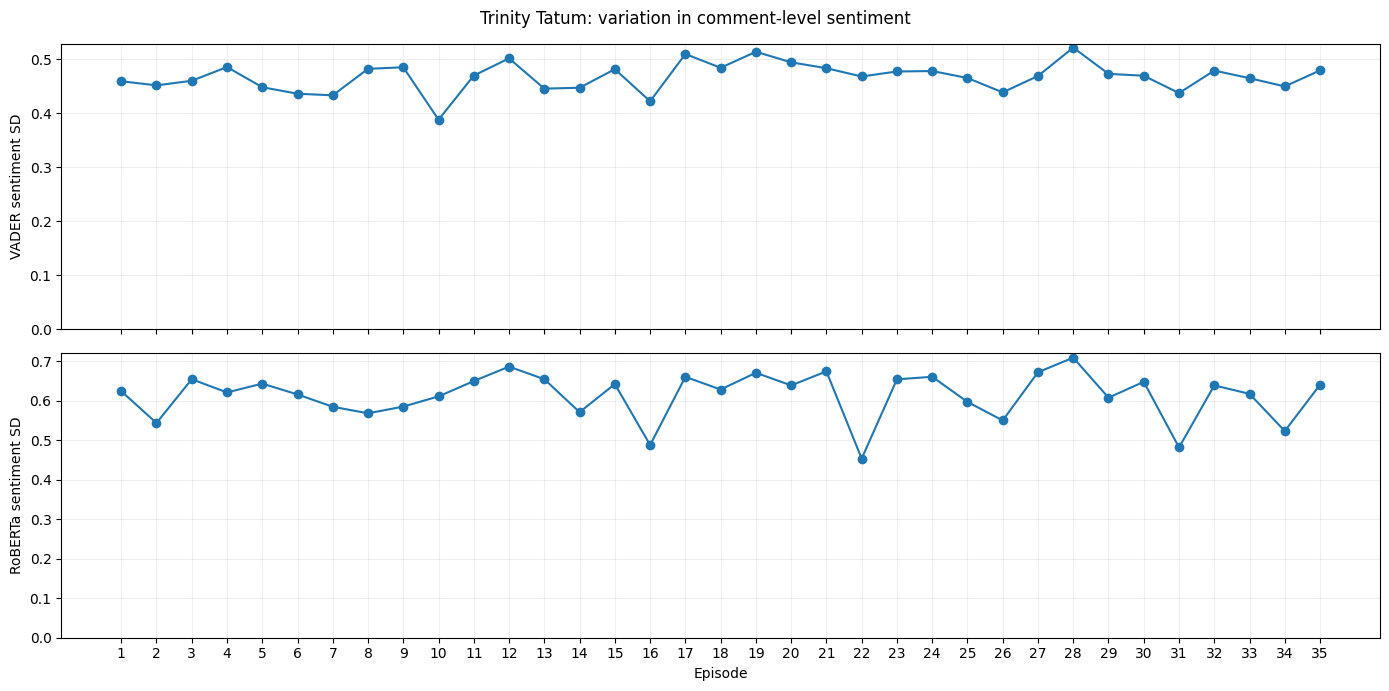

In [134]:
# Use the same selected islander and display threshold as the trend chart.
dispersion_trend = (
    sentiment_by_episode.query("target_islander == @ISLANDER")
    .set_index("episode").reindex(episodes)
)
dispersion_trend.loc[
    dispersion_trend["num_comments"].fillna(0) < MIN_COMMENTS,
    ["vader_std", "roberta_std"],
] = float("nan")

fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
for ax, column, label in zip(
    axes, ["vader_std", "roberta_std"], ["VADER", "RoBERTa"]
):
    ax.plot(dispersion_trend.index, dispersion_trend[column], marker="o")
    ax.set_ylabel(f"{label} sentiment SD")
    ax.set_ylim(bottom=0)
    ax.grid(alpha=0.2)
axes[-1].set_xlabel("Episode")
axes[-1].set_xticks(list(episodes))
fig.suptitle(f"{ISLANDER}: variation in comment-level sentiment")
plt.tight_layout()
plt.show()


### Sentiment Z-scores

In [135]:
relative_islander_summary = overall_islander_summary.copy()

metrics = {
    "vader_mean": "vader_relative_sentiment",
    "roberta_mean": "roberta_relative_sentiment",
}

for source, destination in metrics.items():
    islander_means = relative_islander_summary[source]

    cast_mean = islander_means.mean()
    cast_sd = islander_means.std(ddof=0)

    relative_islander_summary[destination] = (
        (islander_means - cast_mean) / cast_sd
        if cast_sd > 0
        else float("nan")
    )

relative_islander_summary[
    [
        "target_islander",
        "num_comments",
        "vader_mean",
        "vader_relative_sentiment",
        "roberta_mean",
        "roberta_relative_sentiment",
    ]
].sort_values(
    "roberta_relative_sentiment", ascending=False
).round(3)

,target_islander,num_comments,vader_mean,vader_relative_sentiment,roberta_mean,roberta_relative_sentiment
32,Ryan Ten Hulscher,18,0.268,3.255,0.020,2.374
8,Trinity Tatum,11946,0.165,1.529,-0.038,1.890
11,Carl Lee Schmidt,5742,0.162,1.488,-0.043,1.845
26,Chaten Nehra,503,0.159,1.429,-0.058,1.723
27,Ronnie Gunter,395,0.116,0.716,-0.122,1.180
6,Bryce Alakai Dettloff,13657,0.119,0.767,-0.157,0.890
31,Tino Ellis,22,-0.013,-1.440,-0.168,0.801
30,Keyon Harry,24,0.083,0.163,-0.187,0.641
24,Corey Sawyer Jr.,916,0.104,0.509,-0.208,0.461
20,Sean Reifel,2259,0.116,0.709,-0.213,0.421


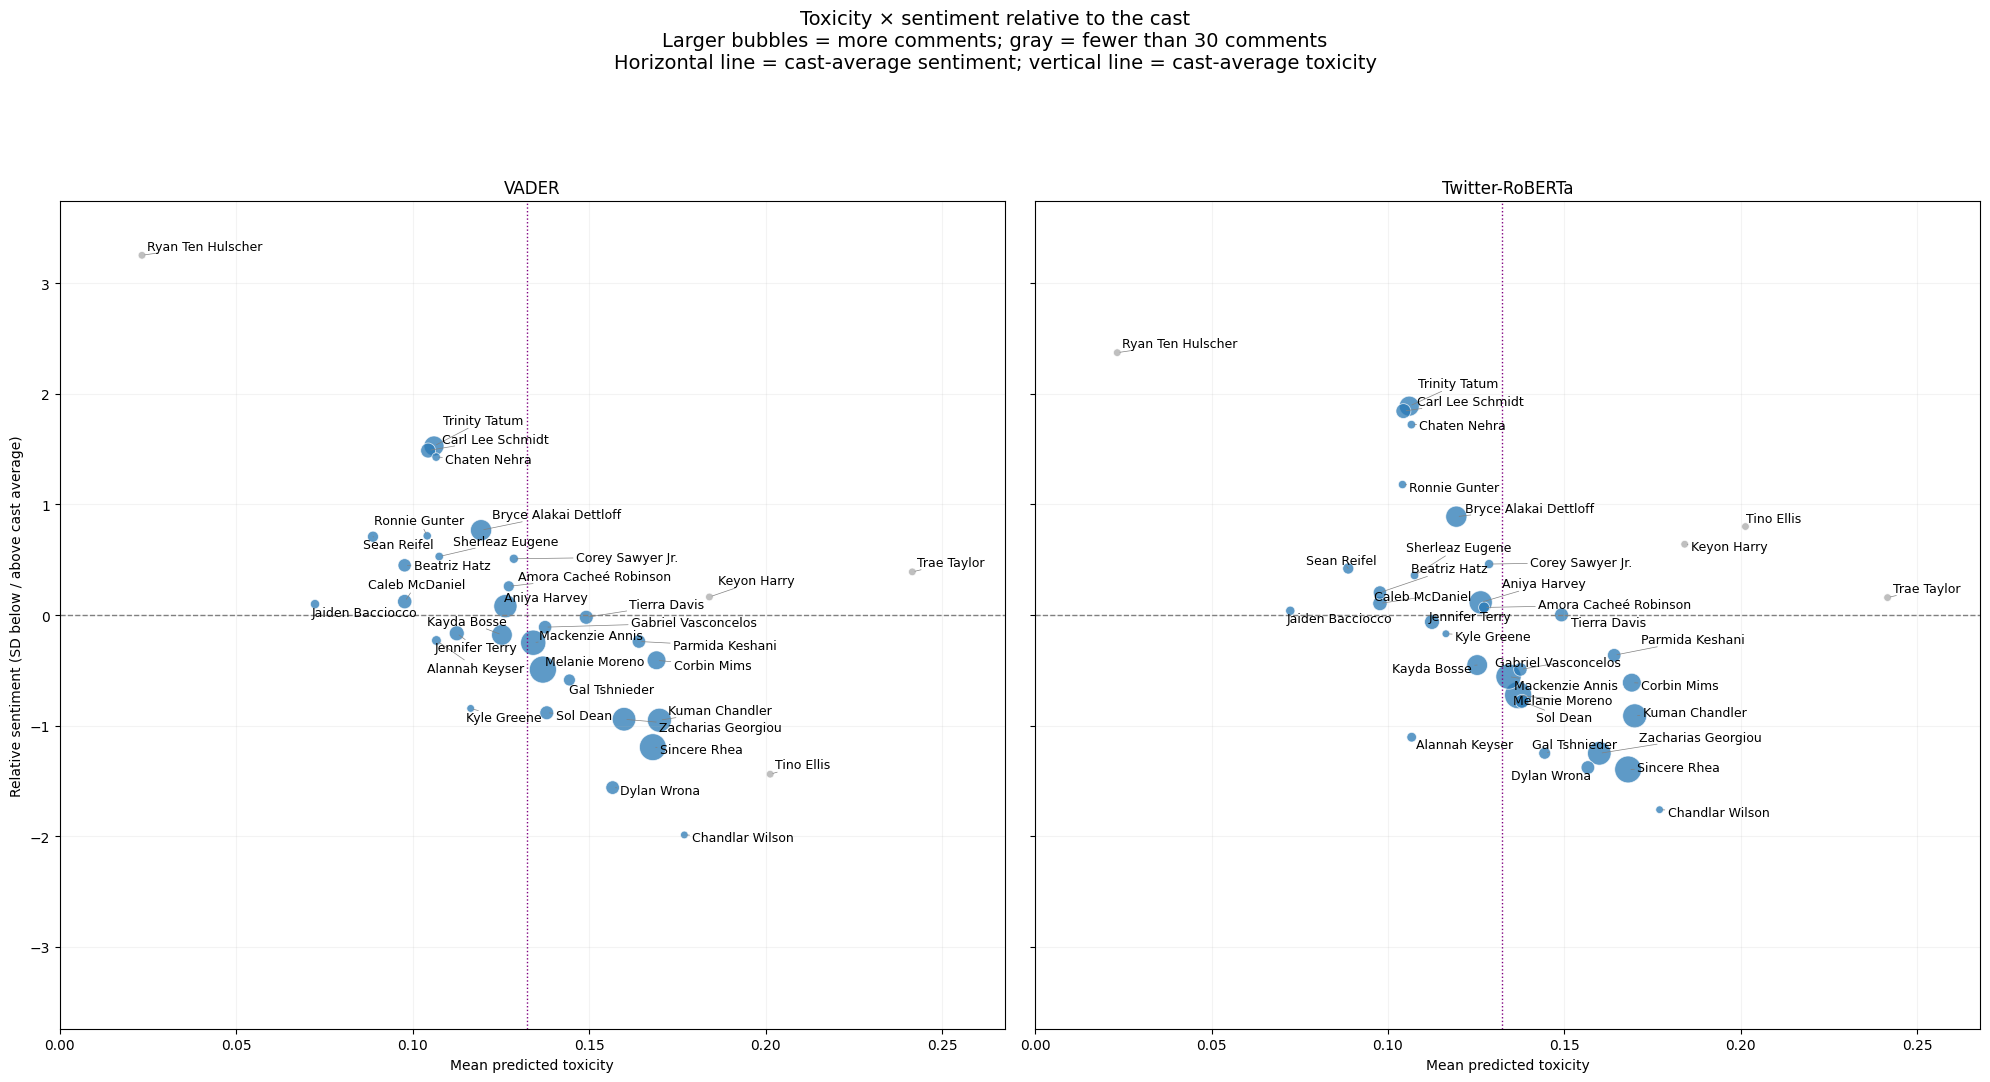

In [136]:
import matplotlib.pyplot as plt
from adjustText import adjust_text

plot_df = relative_islander_summary.copy()

sentiment_columns = [
    "vader_relative_sentiment",
    "roberta_relative_sentiment",
]

sizes = 30 + 350 * (
    plot_df["num_comments"] / plot_df["num_comments"].max()
)
colors = [
    "#aaaaaa" if count < 30 else "#2878B5"
    for count in plot_df["num_comments"]
]

toxicity = plot_df["detoxify_toxicity_mean"]
padding = max((toxicity.max() - toxicity.min()) * 0.12, 0.01)
cast_toxicity_mean = toxicity.mean()

y_extent = max(
    1,
    plot_df[sentiment_columns].abs().max().max() * 1.15,
)

fig, axes = plt.subplots(
    1, 2, figsize=(20, 11), sharex=True, sharey=True
)

for ax, column, title in zip(
    axes, sentiment_columns, ["VADER", "Twitter-RoBERTa"]
):
    ax.scatter(
        toxicity,
        plot_df[column],
        s=sizes,
        c=colors,
        alpha=0.75,
        edgecolors="white",
        linewidths=0.6,
    )

    ax.axhline(0, color="gray", linestyle="--", linewidth=1)
    ax.axvline(
        cast_toxicity_mean,
        color="purple",
        linestyle=":",
        linewidth=1,
    )

    ax.set(
        title=title,
        xlabel="Mean predicted toxicity",
        xlim=(
            max(0, toxicity.min() - padding),
            min(1, toxicity.max() + padding),
        ),
        ylim=(-y_extent, y_extent),
    )
    ax.grid(alpha=0.15)

axes[0].set_ylabel(
    "Relative sentiment (SD below / above cast average)"
)

fig.suptitle(
    "Toxicity × sentiment relative to the cast\n"
    "Larger bubbles = more comments; gray = fewer than 30 comments\n"
    "Horizontal line = cast-average sentiment; "
    "vertical line = cast-average toxicity",
    fontsize=14,
)

plt.tight_layout(rect=[0, 0, 1, 0.91])

for ax, column in zip(axes, sentiment_columns):
    texts = [
        ax.text(
            row["detoxify_toxicity_mean"],
            row[column],
            row["target_islander"],
            fontsize=9,
        )
        for _, row in plot_df.iterrows()
    ]

    adjust_text(
        texts,
        ax=ax,
        expand=(1.15, 1.3),
        arrowprops={"arrowstyle": "-", "color": "gray", "lw": 0.5},
    )

plt.show()

## Aggregate Data

In [137]:
import duckdb
import pandas as pd

aggregations = {
    "num_comments": ("comment_id", "nunique"),
    "num_windows": ("num_windows", "sum"),
    "vader_mean": ("vader_sentiment", "mean"),
    "vader_std": ("vader_sentiment", "std"),
    "roberta_mean": ("roberta_sentiment", "mean"),
    "roberta_std": ("roberta_sentiment", "std"),
    "toxicity_mean": ("detoxify_toxicity", "mean"),
    "insult_mean": ("detoxify_insult", "mean"),
}

# Overall averages.
overall_relative_metrics = (
    comment_islander_scores
    .groupby("target_islander", as_index=False)
    .agg(**aggregations)
)

# Episode-specific averages.
episode_relative_metrics = (
    comment_islander_scores
    .groupby(["episode", "target_islander"], as_index=False)
    .agg(**aggregations)
)

# Retain the reference means and SDs so the scaling is traceable.
for metric in ["vader", "roberta"]:
    source = f"{metric}_mean"

    overall = overall_relative_metrics
    overall[f"{metric}_cast_mean"] = overall[source].mean()
    overall[f"{metric}_cast_sd"] = overall[source].std(ddof=0)

    overall[f"{metric}_relative_sentiment"] = (
        (overall[source] - overall[f"{metric}_cast_mean"])
        / overall[f"{metric}_cast_sd"].where(
            overall[f"{metric}_cast_sd"] > 0
        )
    )

    episode = episode_relative_metrics
    grouped = episode.groupby("episode")[source]

    episode[f"{metric}_cast_mean"] = grouped.transform("mean")
    episode[f"{metric}_cast_sd"] = grouped.transform(
        lambda values: values.std(ddof=0)
    )

    episode[f"{metric}_relative_sentiment"] = (
        (episode[source] - episode[f"{metric}_cast_mean"])
        / episode[f"{metric}_cast_sd"].where(
            episode[f"{metric}_cast_sd"] > 0
        )
    )

overall_relative_metrics = overall_relative_metrics.sort_values(
    "target_islander"
).reset_index(drop=True)

episode_relative_metrics = episode_relative_metrics.sort_values(
    ["episode", "target_islander"]
).reset_index(drop=True)

In [138]:
from pathlib import Path
import duckdb

MOSTLY_THRESHOLD = 0.60
TOXICITY_THRESHOLD = 0.50

label_windows = combined_scores.copy()
share_columns = []

# Window-level sentiment indicators.
for model in ["vader", "roberta"]:
    for sentiment in ["positive", "neutral", "negative"]:
        column = f"{model}_{sentiment}_share"
        label_windows[column] = (
            label_windows[f"{model}_label"].eq(sentiment).astype(float)
        )
        share_columns.append(column)

label_windows["toxicity_flagged_share"] = (
    label_windows["detoxify_toxicity"]
    .ge(TOXICITY_THRESHOLD)
    .astype(float)
)
share_columns.append("toxicity_flagged_share")

# Average windows within each comment–islander pair first.
comment_label_shares = (
    label_windows
    .groupby(
        ["comment_id", "target_islander", "episode"],
        as_index=False,
    )[share_columns]
    .mean()
)

overall_label_shares = (
    comment_label_shares
    .groupby("target_islander", as_index=False)[share_columns]
    .mean()
)

episode_label_shares = (
    comment_label_shares
    .groupby(["episode", "target_islander"], as_index=False)[share_columns]
    .mean()
)


def add_dashboard_labels(metrics, shares, keys):
    # Remove previous derived columns so rerunning is safe.
    derived_columns = [
        *share_columns,
        "vader_discussion_label",
        "roberta_discussion_label",
        "vader_relative_label",
        "roberta_relative_label",
        "model_agreement_label",
        "toxicity_summary",
        "mostly_threshold",
        "toxicity_threshold",
        "min_label_comments",
    ]

    result = (
        metrics.drop(columns=derived_columns, errors="ignore")
        .merge(shares, on=keys, how="left", validate="one_to_one")
    )
    assert result[share_columns].notna().all().all()

    for model in ["vader", "roberta"]:
        label_column = f"{model}_discussion_label"
        result[label_column] = "Mixed reactions"

        for sentiment in ["positive", "neutral", "negative"]:
            result.loc[
                result[f"{model}_{sentiment}_share"] >= MOSTLY_THRESHOLD,
                label_column,
            ] = f"Mostly {sentiment}"

        relative = result[f"{model}_relative_sentiment"]
        relative_label = f"{model}_relative_label"

        result[relative_label] = "At cast average"
        result.loc[relative > 1e-9, relative_label] = "Above cast average"
        result.loc[relative < -1e-9, relative_label] = "Below cast average"
        result.loc[relative.isna(), relative_label] = "Unavailable"

    result["model_agreement_label"] = "Models disagree"
    result.loc[
        result["vader_discussion_label"].eq(
            result["roberta_discussion_label"]
        ),
        "model_agreement_label",
    ] = "Same summary category"

    result["toxicity_summary"] = result["toxicity_flagged_share"].map(
        lambda share: f"{share:.1%} flagged toxic (comment-weighted)"
    )

    # Preserve the labeling rules.
    result["mostly_threshold"] = MOSTLY_THRESHOLD
    result["toxicity_threshold"] = TOXICITY_THRESHOLD

    return result


overall_relative_metrics = add_dashboard_labels(
    overall_relative_metrics,
    overall_label_shares,
    keys=["target_islander"],
)

episode_relative_metrics = add_dashboard_labels(
    episode_relative_metrics,
    episode_label_shares,
    keys=["episode", "target_islander"],
)

# Save updated tables together in DuckDB.
tables_to_save = {
    "overall_relative_metrics": overall_relative_metrics,
    "episode_relative_metrics": episode_relative_metrics,
}

with duckdb.connect(str(db_path)) as con:
    con.execute("CREATE SCHEMA IF NOT EXISTS dashboard")
    con.execute("BEGIN TRANSACTION")

    try:
        for name, table in tables_to_save.items():
            con.register("metrics_export", table)
            con.execute(f"""
                CREATE OR REPLACE TABLE dashboard.{name} AS
                SELECT * FROM metrics_export
            """)

            saved_rows = con.execute(
                f"SELECT COUNT(*) FROM dashboard.{name}"
            ).fetchone()[0]

            assert saved_rows == len(table)
            con.unregister("metrics_export")

        con.execute("COMMIT")
    except Exception:
        con.execute("ROLLBACK")
        raise

# Save CSV copies.
export_dir = (
    Path(db_path).resolve().parent.parent
    / "tables"
    / "sentiment_dashboard"
)
export_dir.mkdir(parents=True, exist_ok=True)

for name, table in tables_to_save.items():
    table.to_csv(
        export_dir / f"{name}.csv",
        index=False,
        encoding="utf-8",
    )
    print(f"Saved {name}: {len(table):,} rows — DuckDB and CSV")

# Preview.
overall_relative_metrics[
    [
        "target_islander",
        "num_comments",
        "vader_discussion_label",
        "roberta_discussion_label",
        "model_agreement_label",
        "roberta_relative_label",
        "toxicity_summary",
    ]
].sort_values("num_comments", ascending=False)

Saved overall_relative_metrics: 34 rows — DuckDB and CSV
Saved episode_relative_metrics: 732 rows — DuckDB and CSV


,target_islander,num_comments,vader_discussion_label,roberta_discussion_label,model_agreement_label,roberta_relative_label,toxicity_summary
21,Melanie Moreno,23557,Mixed reactions,Mixed reactions,Same summary category,Below cast average,12.2% flagged toxic (comment-weighted)
27,Sincere Rhea,23189,Mixed reactions,Mostly negative,Models disagree,Below cast average,15.4% flagged toxic (comment-weighted)
20,Mackenzie Annis,20219,Mixed reactions,Mixed reactions,Same summary category,Below cast average,11.9% flagged toxic (comment-weighted)
18,Kuman Chandler,18048,Mixed reactions,Mixed reactions,Same summary category,Below cast average,15.9% flagged toxic (comment-weighted)
33,Zacharias Georgiou,17351,Mixed reactions,Mixed reactions,Same summary category,Below cast average,14.3% flagged toxic (comment-weighted)
2,Aniya Harvey,16793,Mixed reactions,Mixed reactions,Same summary category,Above cast average,11.3% flagged toxic (comment-weighted)
4,Bryce Alakai Dettloff,13657,Mixed reactions,Mixed reactions,Same summary category,Above cast average,10.4% flagged toxic (comment-weighted)
16,Kayda Bosse,12913,Mixed reactions,Mixed reactions,Same summary category,Below cast average,11.1% flagged toxic (comment-weighted)
32,Trinity Tatum,11946,Mixed reactions,Mixed reactions,Same summary category,Above cast average,9.3% flagged toxic (comment-weighted)
9,Corbin Mims,10266,Mixed reactions,Mixed reactions,Same summary category,Below cast average,15.4% flagged toxic (comment-weighted)


In [139]:
from pathlib import Path

tables_to_save = {
    "overall_relative_metrics": overall_relative_metrics,
    "episode_relative_metrics": episode_relative_metrics,
}

with duckdb.connect(str(db_path)) as con:
    con.execute("CREATE SCHEMA IF NOT EXISTS dashboard")
    con.execute("BEGIN TRANSACTION")

    try:
        for name, table in tables_to_save.items():
            con.register("metrics_export", table)

            con.execute(f"""
                CREATE OR REPLACE TABLE dashboard.{name} AS
                SELECT * FROM metrics_export
            """)

            saved_rows = con.execute(
                f"SELECT COUNT(*) FROM dashboard.{name}"
            ).fetchone()[0]

            assert saved_rows == len(table)
            con.unregister("metrics_export")

        con.execute("COMMIT")
    except Exception:
        con.execute("ROLLBACK")
        raise

export_dir = (
    Path(db_path).resolve().parent.parent
    / "tables"
    / "sentiment_dashboard"
)
export_dir.mkdir(parents=True, exist_ok=True)

for name, table in tables_to_save.items():
    table.to_csv(export_dir / f"{name}.csv", index=False, encoding="utf-8")
    print(f"Saved {name}: {len(table):,} rows — DuckDB and CSV")

Saved overall_relative_metrics: 34 rows — DuckDB and CSV
Saved episode_relative_metrics: 732 rows — DuckDB and CSV


## Villa Events — Final Eight

Load the event assignments directly from notebook 04 without executing its code. Finalists are selected from nonempty `final_placement` values in the cast metadata. Use the saved episode-level z-scores: the reference is all islanders with scored comments in each episode, not just the final eight. Zero means that episode's cast average; moving z-scores reflect relative standing, not necessarily a change in absolute sentiment.

All available episodes use the same markers; missing episodes remain gaps. Aftersun annotations are omitted. Event lines show timing only, not causal effects. The event dates below reproduce 04's annotations rather than independently verifying them.


In [140]:
import ast
import json
from pathlib import Path

import duckdb
import numpy as np
import pandas as pd

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
db_path = project_root / "data" / "love_island_reddit.duckdb"

# Read only literal assignments; never execute notebook 04.
notebook04 = json.loads(
    (project_root / "notebooks" / "04-attention-metrics.ipynb").read_text()
)
wanted = {"recoupling_eps", "casa_start", "casa_recoupling"}
event_settings = {}
for notebook_cell in notebook04["cells"]:
    if notebook_cell["cell_type"] != "code":
        continue
    tree = ast.parse("".join(notebook_cell["source"]))
    for statement in tree.body:
        if isinstance(statement, ast.Assign):
            for target in statement.targets:
                if isinstance(target, ast.Name) and target.id in wanted:
                    value = ast.literal_eval(statement.value)
                    if target.id in event_settings and event_settings[target.id] != value:
                        raise ValueError(f"Conflicting event definitions in 04: {target.id}")
                    event_settings[target.id] = value
assert wanted == set(event_settings), "Missing event definitions in notebook 04."

villa_events = pd.DataFrame(
    [{"episode": ep, "event": "Recoupling"} for ep in event_settings["recoupling_eps"]]
    + [{"episode": event_settings["casa_start"], "event": "Casa Amor begins"}]
    + [{"episode": event_settings["casa_recoupling"], "event": "Casa recoupling"}]
).sort_values(["episode", "event"]).reset_index(drop=True)

cast = pd.read_csv(project_root / "data" / "metadata" / "islander_metadata.csv")
placement = cast["final_placement"].fillna("").str.strip()
finalists = cast.loc[placement.ne(""), ["islander", "final_placement"]].copy()
placement_order = {"Winner": 1, "Runner-up": 2, "Third Place": 3, "Fourth Place": 4}
finalists["placement_order"] = finalists["final_placement"].map(placement_order)
finalists = finalists.sort_values(["placement_order", "islander"])
assert len(finalists) == 8 and finalists["islander"].is_unique

with duckdb.connect(str(db_path)) as con:
    episode_metrics = con.execute("SELECT * FROM dashboard.episode_relative_metrics").df()
assert not episode_metrics.duplicated(["episode", "target_islander"]).any()
final_eight_episode_metrics = episode_metrics.merge(
    finalists, left_on="target_islander", right_on="islander",
    how="inner", validate="many_to_one",
).drop(columns="islander")
assert final_eight_episode_metrics["target_islander"].nunique() == 8

print("Final eight:", ", ".join(finalists["islander"]))
villa_events


Final eight: Bryce Alakai Dettloff, Trinity Tatum, Aniya Harvey, Carl Lee Schmidt, Melanie Moreno, Sincere Rhea, Kayda Bosse, Zacharias Georgiou


,episode,event
0,5,Recoupling
1,13,Recoupling
2,18,Casa Amor begins
3,21,Casa recoupling
4,27,Recoupling


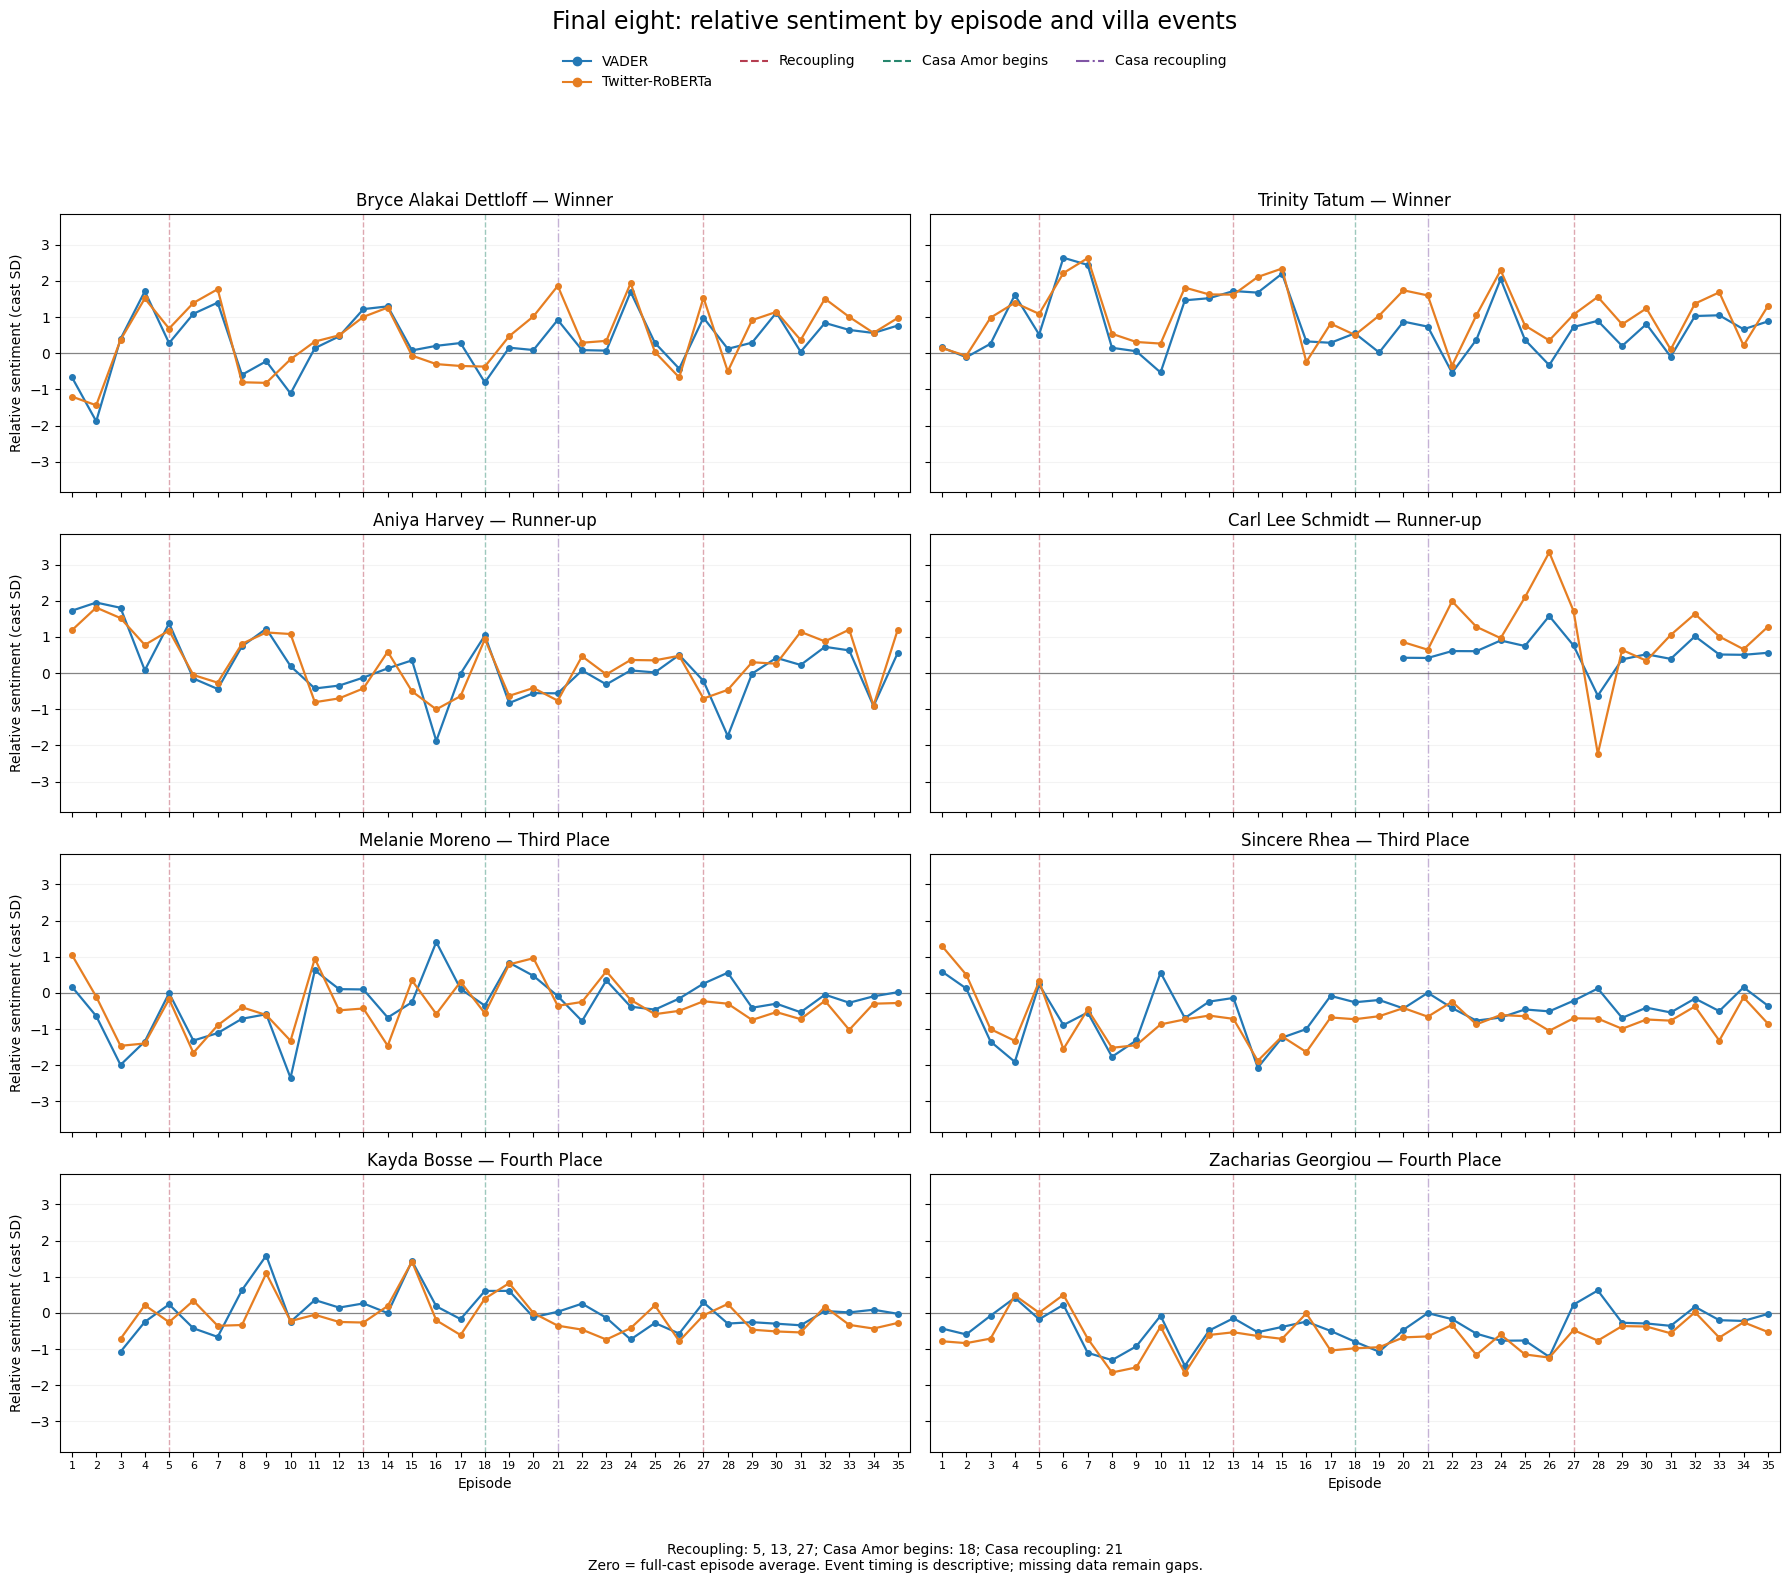

In [141]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

model_styles = {
    "vader_relative_sentiment": ("VADER", "#2378b5"),
    "roberta_relative_sentiment": ("Twitter-RoBERTa", "#e67e22"),
}
event_styles = {
    "Recoupling": ("#b53d50", "--"),
    "Casa Amor begins": ("#26866d", "--"),
    "Casa recoupling": ("#8055a5", "-."),
}
episode_axis = np.arange(int(episode_metrics.episode.min()), int(episode_metrics.episode.max()) + 1)
extent = final_eight_episode_metrics[list(model_styles)].abs().max().max()
assert np.isfinite(extent), "No finite relative sentiment scores."
extent = max(1, extent * 1.15)

fig, axes = plt.subplots(4, 2, figsize=(18, 16), sharex=True, sharey=True)
for ax, finalist in zip(axes.flat, finalists.itertuples(index=False)):
    data = (
        final_eight_episode_metrics.query("target_islander == @finalist.islander")
        .set_index("episode").reindex(episode_axis)
    )
    for event in villa_events.itertuples(index=False):
        color, style = event_styles[event.event]
        ax.axvline(event.episode, color=color, linestyle=style, alpha=0.45, lw=1, zorder=0)
    ax.axhline(0, color="#555555", lw=0.9, alpha=0.7)
    for column, (label, color) in model_styles.items():
        ax.plot(data.index, data[column], color=color, lw=1.6,
                marker="o", markersize=4, zorder=2)
    ax.set_title(f"{finalist.islander} — {finalist.final_placement}", fontsize=12)
    ax.set_ylim(-extent, extent)
    ax.set_xlim(episode_axis.min() - 0.5, episode_axis.max() + 0.5)
    ax.set_xticks(episode_axis)
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="y", alpha=0.15)

for ax in axes[:, 0]:
    ax.set_ylabel("Relative sentiment (cast SD)")
for ax in axes[-1, :]:
    ax.set_xlabel("Episode")

legend = [Line2D([0], [0], color=color, marker="o", label=label)
          for label, color in model_styles.values()]
legend += [Line2D([0], [0], color=color, linestyle=style, label=label)
           for label, (color, style) in event_styles.items()]
fig.suptitle("Final eight: relative sentiment by episode and villa events", fontsize=17, y=0.99)
fig.legend(handles=legend, loc="upper center", bbox_to_anchor=(0.5, 0.97), ncol=4, frameon=False)
event_key = "; ".join(
    f"{label}: " + ", ".join(map(str, villa_events.loc[villa_events.event.eq(label), "episode"]))
    for label in event_styles
)
fig.text(0.5, 0.015, event_key + "\nZero = full-cast episode average. Event timing is descriptive; missing data remain gaps.",
         ha="center", fontsize=10)
fig.tight_layout(rect=[0, 0.055, 1, 0.91])

figure_dir = project_root / "viz"
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_dir / "final_eight_relative_sentiment_events.png", dpi=180, bbox_inches="tight")
plt.show()


## Sample source windows for qualitative ChatGPT analysis (no API)

Export one CSV per islander, targeting **120,000 characters of window + full-comment context**. Fixed seed 42 gives reproducible random draws. Choose one existing target window per unique comment, then balance text coverage across episodes; episodes with fewer comments contribute all available text and the remaining budget goes to other episodes. Keep every observed episode represented and preserve individual windows/comments intact, allowing the last draw to slightly exceed the target. Smaller corpora produce smaller files.

This is an episode-balanced qualitative sample, not a volume-weighted estimate of the entire audience. No sentiment scores or LLM calls are used. Source assignments and IDs are preserved, the database is read-only, and missing fields block export with a report. Checks cover source text, episode coverage, duplicates, reproducibility, and CSV round trips.

Upload **one `__sample.csv` plus `UPLOAD_PROMPT.txt`** per ChatGPT conversation. Use the new `qualitative_samples` folder; the older full-export batches are no longer needed for this workflow.

In [142]:
from pathlib import Path
import importlib.util

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
spec = importlib.util.spec_from_file_location(
    "export_qualitative_sample", project_root / "code" / "export_qualitative_sample.py"
)
qualitative_export = importlib.util.module_from_spec(spec)
spec.loader.exec_module(qualitative_export)
qualitative_manifest, qualitative_validation = qualitative_export.export_sample(
    project_root / "data" / "love_island_reddit.duckdb",
    project_root / "tables" / "sentiment_dashboard" / "qualitative_samples",
)
display(qualitative_manifest.head())

{
  "source_windows": 244397,
  "unique_comment_islander_episode_units": 223390,
  "islanders": 34,
  "episode_groups": 732,
  "sampled_comments": 13255,
  "missing_fields": {
    "window_id": 0,
    "comment_id": 0,
    "target_islander": 0,
    "episode": 0,
    "window_text": 0
  },
  "context_fallback_units": 0,
  "target_text_characters": 120000,
  "seed": 42,
  "validation": "Passed source text/assignment checks, CSV round trips, unique comments, every episode covered, and repeatability under source reordering."
}
Exports: /Users/edieespejo/GitHub/data-by-edie/004-love-island/tables/sentiment_dashboard/qualitative_samples


,islander,filename,seed,target_characters,sampled_characters,available_characters,csv_characters,sampled_comments,available_comments,episodes,all_available_comments_used,sha256
0,Alannah Keyser,alannah-keyser__sample.csv,42,120000,120056,268257,183199,508,1250,16,False,47b41f29ceec6c1ba2d7341d9f42504677bed421936377009cbf466d46a80fb0
1,Amora Cacheé Robinson,amora-cachee-robinson__sample.csv,42,120000,120845,482231,196479,576,2177,19,False,1b1f08291e85214acadb2d592246e3f834fecd1cc5efc6a881127dc03ce54746
2,Aniya Harvey,aniya-harvey__sample.csv,42,120000,120189,4395129,171686,421,16793,35,False,506b15ab4426556034f92249d3b43500bbc7842d5bd79b2ba52a759d86638d85
3,Beatriz Hatz,beatriz-hatz__sample.csv,42,120000,120094,1283014,163281,352,4148,35,False,d51e680a8ebc760b928d596794c51487c62a1bd8091e57e44ac500315708719a
4,Bryce Alakai Dettloff,bryce-alakai-dettloff__sample.csv,42,120000,120132,3235867,183454,483,13657,35,False,93d954c7f4a413a5b88511662af3e14d06ab68ae78c23cd0399e25d7d0013189


Read in the OpenAI output.

In [143]:
from pathlib import Path
import pandas as pd

csv_root = Path("/Users/edieespejo/GitHub/data-by-edie/004-love-island/data/openai")

csv_files = sorted(
    csv_root.glob(
        "*__community_perceptions.csv"
    )
)

if not csv_files:
    raise FileNotFoundError(f"No community perception CSVs found in {csv_root}")

community_perceptions = pd.concat(
    [pd.read_csv(path, dtype={"episode": "string"}) for path in csv_files],
    ignore_index=True,
)

binary_columns = [
    "approval",
    "winner_support",
    "genuine",
    "trustworthy",
    "entertaining",
    "winner_prediction",
]

community_perceptions[binary_columns] = (
    community_perceptions[binary_columns].astype("Int64")
)
community_perceptions["evidence_count"] = (
    community_perceptions["evidence_count"].astype("Int64")
)

# Check that each islander–episode combination appears only once.
duplicates = community_perceptions.duplicated(
    ["islander", "episode"], keep=False
)
if duplicates.any():
    raise ValueError(
        "Duplicate islander–episode rows:\n"
        + community_perceptions.loc[
            duplicates, ["islander", "episode"]
        ].to_string(index=False)
    )

# Separate overall assessments from episode assessments.
overall_perceptions = community_perceptions.loc[
    community_perceptions["episode"].eq("overall")
].copy()

episode_perceptions = community_perceptions.loc[
    community_perceptions["episode"].ne("overall")
].copy()

episode_perceptions["episode"] = (
    episode_perceptions["episode"].astype("Int64")
)
episode_perceptions = episode_perceptions.sort_values(
    ["islander", "episode"]
).reset_index(drop=True)

print(
    f"Loaded {len(csv_files)} files, "
    f"{community_perceptions['islander'].nunique()} islanders, "
    f"{len(community_perceptions)} rows."
)

display(community_perceptions.head())

Loaded 34 files, 34 islanders, 766 rows.


,islander,episode,approval,winner_support,genuine,trustworthy,entertaining,winner_prediction,evidence_count,confidence
0,Alannah Keyser,overall,0,0,0,0,0,<NA>,508,high
1,Alannah Keyser,16,<NA>,<NA>,<NA>,<NA>,<NA>,<NA>,1,low
2,Alannah Keyser,17,0,0,0,0,0,<NA>,76,high
3,Alannah Keyser,18,0,0,0,0,0,<NA>,70,high
4,Alannah Keyser,19,0,0,<NA>,<NA>,0,<NA>,77,high


## Community perception standouts and dashboard exports

User-confirmed coding: **1 = discussion supports the perception; 0 = opposes it; blank = unclear/not discussed**. These are ChatGPT assessments of sampled text, not audience vote percentages, personality facts, or calibrated probabilities. Confidence is the imported model assessment. Winner support means wanting someone to win; winner prediction is a separate perception.

Overall binary columns have ties rather than a unique winner. The summary below shows all supported perceptions and a separate episode consistency table (supported episodes / assessed episodes); unknown episodes are excluded from that denominator and shown explicitly. No low-count islanders are hidden. A 100% result over one assessed episode is not equivalent to one over many episodes. The number of supported columns is a descriptive count, not a validated composite score.

The source CSVs are preserved. Save overall/episode assessments with sample counts, source-file hashes and coding definitions, plus standout, consistency, and coverage tables to `dashboard` in DuckDB and matching CSVs. The coverage audit checks all 34 islanders and 732 islander-episode groups; rerun this section after adding or replacing source files.

In [144]:
from pathlib import Path
import importlib.util
import pandas as pd

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
spec = importlib.util.spec_from_file_location("perception_summary", project_root / "code" / "summarize_community_perceptions.py")
perception_summary = importlib.util.module_from_spec(spec)
spec.loader.exec_module(perception_summary)
perception_tables = perception_summary.build_and_save(project_root)
overall_community_perceptions = perception_tables["overall_community_perceptions"]
episode_community_perceptions = perception_tables["episode_community_perceptions"]
community_perception_standouts = perception_tables["community_perception_standouts"]
community_perception_episode_consistency = perception_tables["community_perception_episode_consistency"]
community_perception_coverage = perception_tables["community_perception_coverage"]
for name, table in perception_tables.items():
    print(f"Saved dashboard.{name}: {len(table):,} rows — DuckDB + CSV")
print("Missing output:")
display(community_perception_coverage.query("status != 'present'").groupby(["target_islander", "scope", "status"]).size().rename("missing_rows").reset_index())
print("Overall standouts: every islander coded 1 in each column (ties retained)")
with pd.option_context("display.max_colwidth", None):
    display(community_perception_standouts.groupby("metric").agg(
        islanders=("target_islander", ", ".join), count=("target_islander", "size")
    ).reset_index())
print("Broadest supported overall portrayals — descriptive counts, not a composite score")
display(overall_community_perceptions.sort_values(
    ["overall_columns_coded_1", "target_islander"], ascending=[False, True]
)[["target_islander", "overall_columns_coded_1", "overall_columns_assessed", "confidence", "sampled_comments"]].head(10))
print("Episode consistency — top three ranks per column, including ties; inspect denominators")
display(community_perception_episode_consistency.query("rank_within_metric <= 3").sort_values(
    ["metric", "rank_within_metric", "episodes_assessed"], ascending=[True, True, False]
).reset_index(drop=True))

Saved dashboard.overall_community_perceptions: 34 rows — DuckDB + CSV
Saved dashboard.episode_community_perceptions: 732 rows — DuckDB + CSV
Saved dashboard.community_perception_standouts: 61 rows — DuckDB + CSV
Saved dashboard.community_perception_episode_consistency: 204 rows — DuckDB + CSV
Saved dashboard.community_perception_coverage: 766 rows — DuckDB + CSV
Missing output:


,target_islander,scope,status,missing_rows


Overall standouts: every islander coded 1 in each column (ties retained)


,metric,islanders,count
0,approval,"Amora Cacheé Robinson, Aniya Harvey, Beatriz Hatz, Bryce Alakai Dettloff, Caleb McDaniel, Carl Lee Schmidt, Chandlar Wilson, Chaten Nehra, Gabriel Vasconcelos, Jaiden Bacciocco, Jennifer Terry, Kayda Bosse, Keyon Harry, Melanie Moreno, Ronnie Gunter, Ryan Ten Hulscher, Sean Reifel, Sol Dean, Tino Ellis, Trinity Tatum",20
1,entertaining,"Amora Cacheé Robinson, Aniya Harvey, Beatriz Hatz, Bryce Alakai Dettloff, Carl Lee Schmidt, Chaten Nehra, Corbin Mims, Corey Sawyer Jr., Gabriel Vasconcelos, Jennifer Terry, Kayda Bosse, Mackenzie Annis, Melanie Moreno, Parmida Keshani, Ronnie Gunter, Sean Reifel, Tino Ellis, Trinity Tatum",18
2,genuine,"Aniya Harvey, Beatriz Hatz, Bryce Alakai Dettloff, Carl Lee Schmidt, Jennifer Terry, Melanie Moreno, Sean Reifel, Trinity Tatum",8
3,trustworthy,"Beatriz Hatz, Bryce Alakai Dettloff, Carl Lee Schmidt, Gabriel Vasconcelos, Jennifer Terry, Parmida Keshani, Sean Reifel, Trinity Tatum",8
4,winner_prediction,"Bryce Alakai Dettloff, Chandlar Wilson, Trinity Tatum",3
5,winner_support,"Aniya Harvey, Bryce Alakai Dettloff, Carl Lee Schmidt, Trinity Tatum",4


Broadest supported overall portrayals — descriptive counts, not a composite score


,target_islander,overall_columns_coded_1,overall_columns_assessed,confidence,sampled_comments
4,Bryce Alakai Dettloff,6,6,high,483
32,Trinity Tatum,6,6,high,392
6,Carl Lee Schmidt,5,5,high,583
2,Aniya Harvey,4,4,medium,421
3,Beatriz Hatz,4,4,medium,352
15,Jennifer Terry,4,5,medium,464
25,Sean Reifel,4,4,medium,330
12,Gabriel Vasconcelos,3,3,medium,326
21,Melanie Moreno,3,4,medium,433
1,Amora Cacheé Robinson,2,5,medium,576


Episode consistency — top three ranks per column, including ties; inspect denominators


,target_islander,metric,episodes_returned,episodes_coded_1,episodes_coded_0,episodes_unknown,episodes_assessed,share_assessed_episodes_coded_1,rank_within_metric
0,Trinity Tatum,approval,35,33,0,2,33,1.0,1
1,Sean Reifel,approval,33,21,0,12,21,1.0,1
2,Carl Lee Schmidt,approval,16,15,0,1,15,1.0,1
3,Tino Ellis,approval,2,2,0,0,2,1.0,1
4,Chandlar Wilson,approval,10,1,0,9,1,1.0,1
5,Ryan Ten Hulscher,approval,4,1,0,3,1,1.0,1
6,Bryce Alakai Dettloff,entertaining,35,24,0,11,24,1.0,1
7,Trinity Tatum,entertaining,35,21,0,14,21,1.0,1
8,Carl Lee Schmidt,entertaining,16,11,0,5,11,1.0,1
9,Sean Reifel,entertaining,33,11,0,22,11,1.0,1


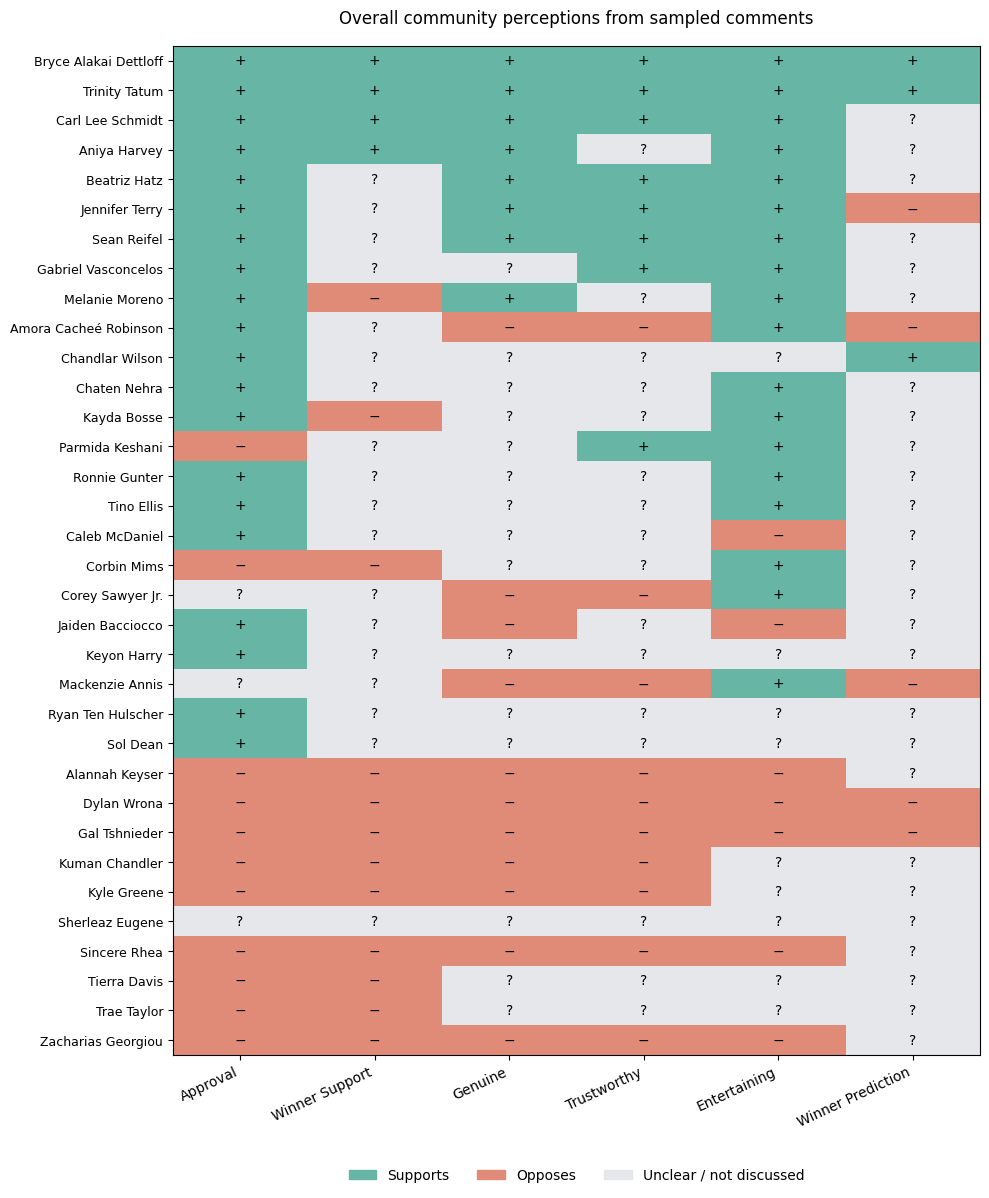

In [145]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

columns = perception_summary.METRICS
plot_data = overall_community_perceptions.sort_values(
    ["overall_columns_coded_1", "target_islander"], ascending=[False, True]
).set_index("target_islander")[columns]
values = plot_data.astype(float).fillna(-1).to_numpy()
fig, ax = plt.subplots(figsize=(10, 12))
ax.imshow(values, cmap=ListedColormap(["#e5e7eb", "#df8b78", "#67b6a5"]),
          norm=BoundaryNorm([-1.5, -0.5, 0.5, 1.5], 3), aspect="auto")
ax.set_yticks(range(len(plot_data)), plot_data.index, fontsize=9)
ax.set_xticks(range(len(columns)), [c.replace("_", " ").title() for c in columns], rotation=25, ha="right")
for i in range(len(plot_data)):
    for j in range(len(columns)):
        ax.text(j, i, {1: "+", 0: "−", -1: "?"}[int(values[i,j])], ha="center", va="center")
ax.set_title("Overall community perceptions from sampled comments", pad=16)
ax.legend(handles=[Patch(color=c, label=l) for c,l in [
    ("#67b6a5", "Supports"), ("#df8b78", "Opposes"), ("#e5e7eb", "Unclear / not discussed")]],
    loc="upper center", bbox_to_anchor=(0.5, -0.10), ncol=3, frameon=False)
fig.tight_layout()
figure_path = project_root / "viz" / "overall_community_perceptions.png"
figure_path.parent.mkdir(exist_ok=True)
fig.savefig(figure_path, dpi=160, bbox_inches="tight")
plt.show()

## Focus on approval — episode by episode

Use the existing ChatGPT approval codes only: **1 = approval, 0 = disapproval, blank = unclear/not discussed**. Gray is an existing assessment with unknown approval; white means no episode assessment. Neither means neutral or disapproval. The plot includes every available islander without a comment-count cutoff.

Kenzie's overall blank is the imported overall judgment, not a calculated average of episode codes. Her episode sequence and sample excerpts show shifting reactions, but no explicit rationale for that overall blank was supplied. Keep it unknown rather than replacing it with a majority vote. The detailed timeline shows sampled-comment counts for context; counts are not approval votes. Full approval data are already saved in `dashboard.overall_community_perceptions` and `dashboard.episode_community_perceptions`.

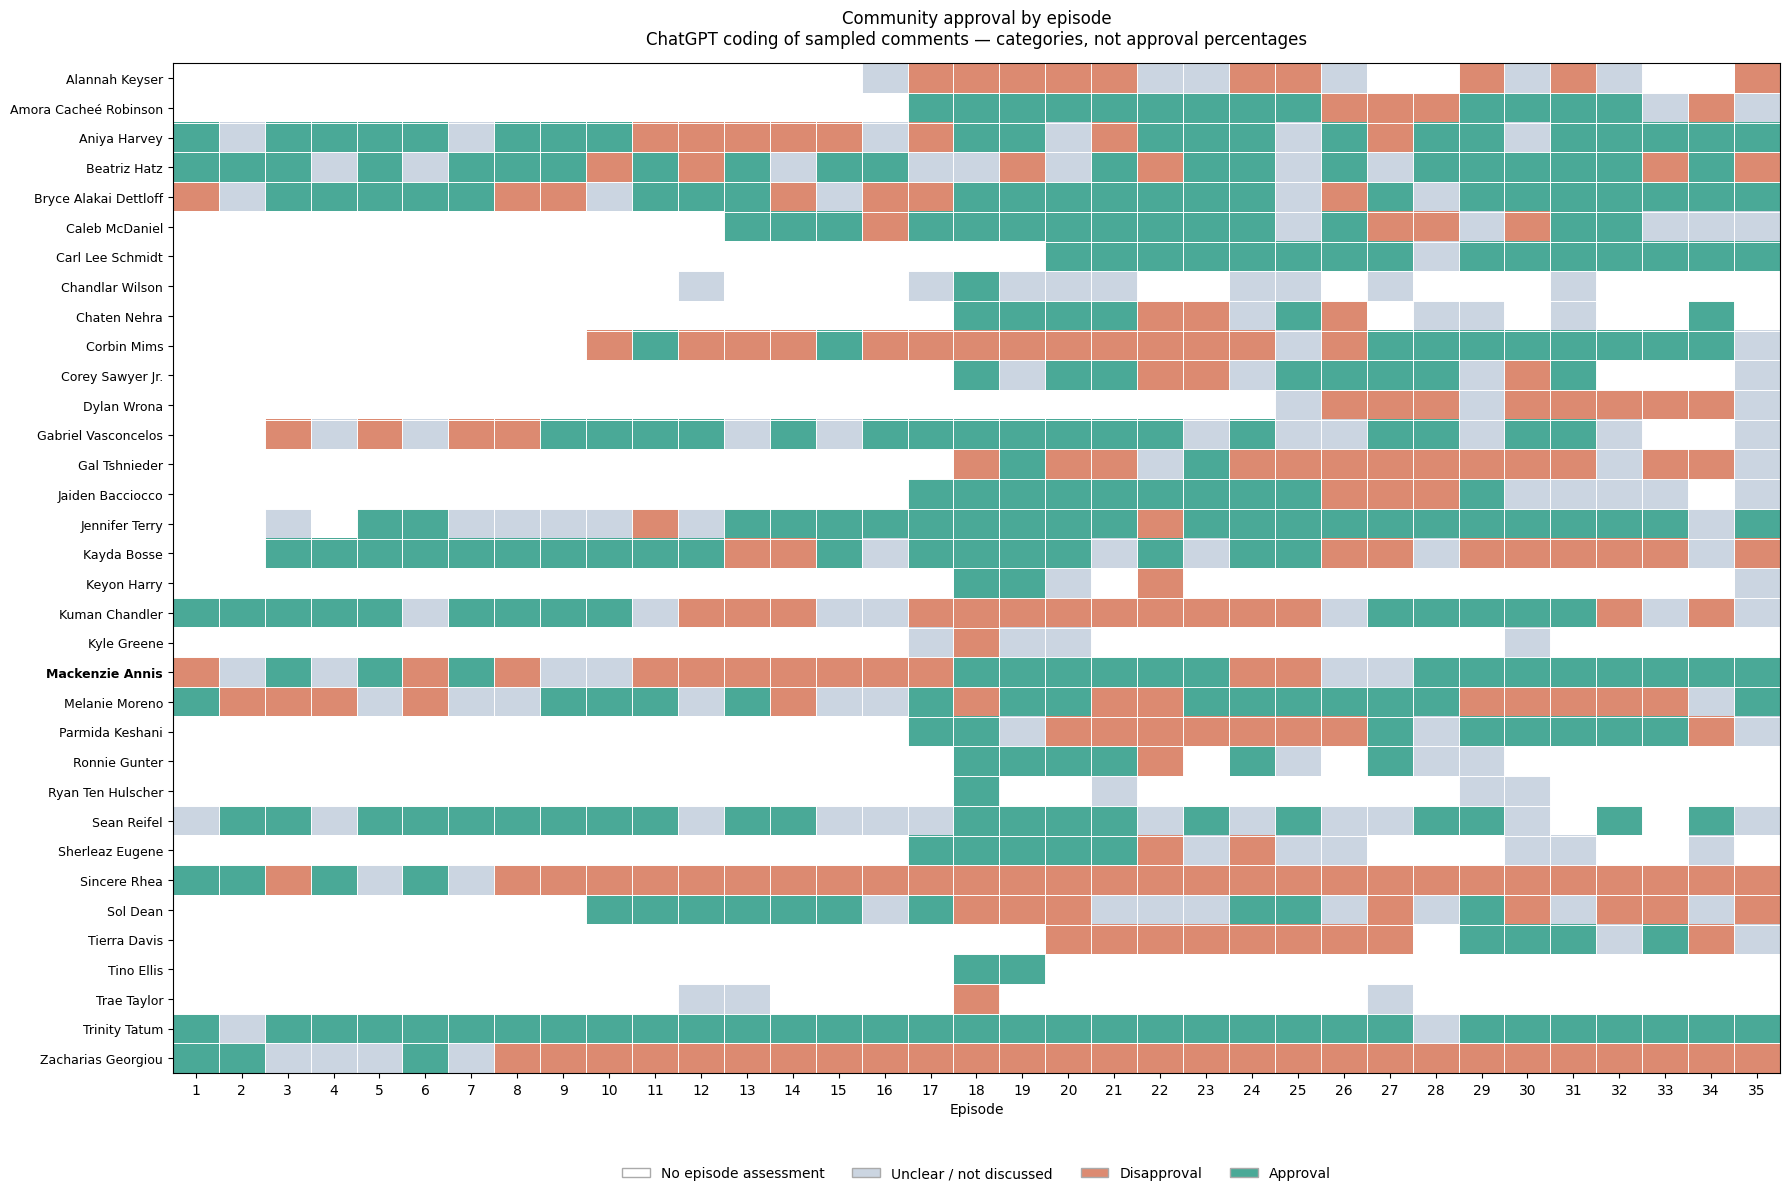

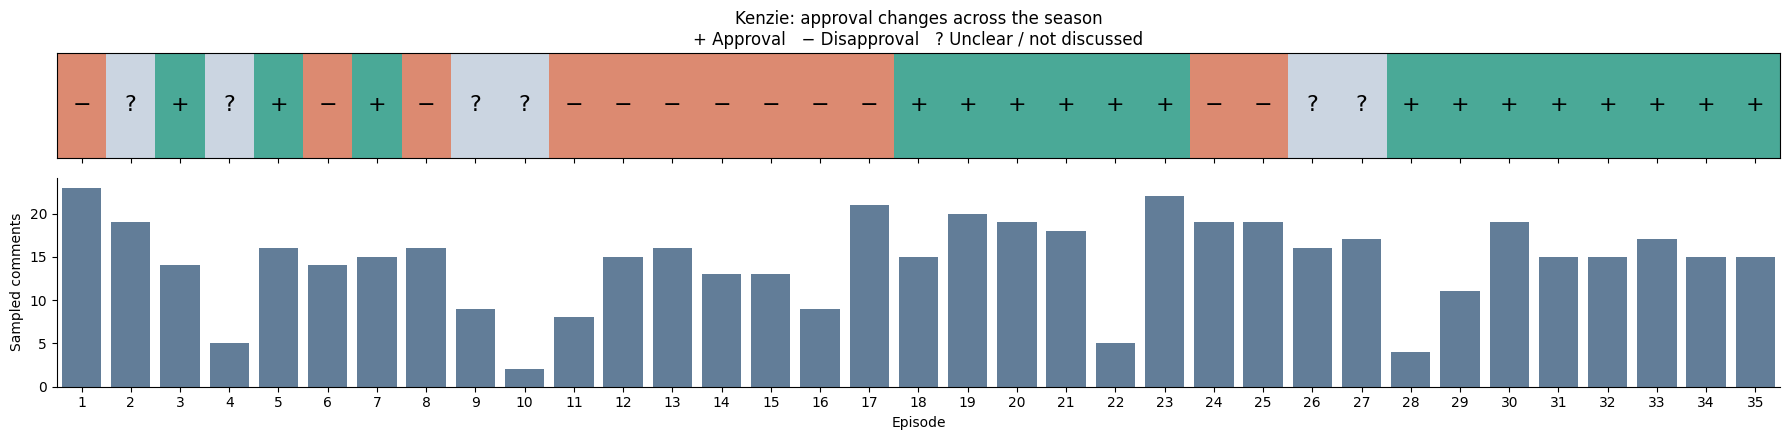

Kenzie episode counts (unknowns are not counted as disapproval):
approval
Approval                   17
Disapproval                12
Unclear / not discussed     6


,episode,approval,sampled_comments,confidence
0,1,0,23,low
1,2,<NA>,19,low
2,3,1,14,medium
3,4,<NA>,5,low
4,5,1,16,low
5,6,0,14,medium
6,7,1,15,low
7,8,0,16,high
8,9,<NA>,9,low
9,10,<NA>,2,low


In [146]:
from pathlib import Path
import duckdb
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
with duckdb.connect(str(project_root / "data" / "love_island_reddit.duckdb"), read_only=True) as con:
    approval_by_episode = con.execute("SELECT target_islander, episode, approval, sampled_comments, confidence FROM dashboard.episode_community_perceptions").df()
    approval_overall = con.execute("SELECT target_islander, approval FROM dashboard.overall_community_perceptions").df()

# Distinguish an assessed episode with unknown approval from an absent episode row.
episodes = list(range(int(approval_by_episode.episode.min()), int(approval_by_episode.episode.max()) + 1))
names = sorted(approval_overall.target_islander)
approval_grid = pd.DataFrame(-2, index=names, columns=episodes)
for row in approval_by_episode.itertuples():
    approval_grid.loc[row.target_islander, row.episode] = -1 if pd.isna(row.approval) else int(row.approval)
colors = ["#ffffff", "#cbd5e1", "#dc8a71", "#4aa997"]
cmap = ListedColormap(colors)
norm = BoundaryNorm([-2.5, -1.5, -0.5, 0.5, 1.5], 4)
legend = [Patch(facecolor=c, edgecolor="#aaaaaa", label=l) for c,l in zip(colors,
          ["No episode assessment", "Unclear / not discussed", "Disapproval", "Approval"])]
fig, ax = plt.subplots(figsize=(18, 12))
ax.imshow(approval_grid, cmap=cmap, norm=norm, aspect="auto")
ax.set_xticks(range(len(episodes)), episodes)
ax.set_yticks(range(len(names)), names, fontsize=9)
for tick in ax.get_yticklabels():
    if tick.get_text() == "Mackenzie Annis": tick.set_fontweight("bold")
ax.set_xticks(np.arange(-.5, len(episodes), 1), minor=True)
ax.set_yticks(np.arange(-.5, len(names), 1), minor=True)
ax.grid(which="minor", color="white", linewidth=.7)
ax.tick_params(which="minor", bottom=False, left=False)
ax.set_xlabel("Episode")
ax.set_title("Community approval by episode\nChatGPT coding of sampled comments — categories, not approval percentages", pad=14)
ax.legend(handles=legend, loc="upper center", bbox_to_anchor=(.5, -.08), ncol=4, frameon=False)
fig.tight_layout()
figure_dir = project_root / "viz"
fig.savefig(figure_dir / "community_approval_by_episode.png", dpi=160, bbox_inches="tight")
plt.show()

kenzie_approval = approval_by_episode.loc[approval_by_episode.target_islander.eq("Mackenzie Annis")].set_index("episode").reindex(episodes)
fig, (ax, counts) = plt.subplots(2, 1, figsize=(18, 4.5), sharex=True, gridspec_kw={"height_ratios": [1, 2]})
values = approval_grid.loc[["Mackenzie Annis"]].to_numpy()
ax.imshow(values, cmap=cmap, norm=norm, aspect="auto")
for i, value in enumerate(values[0]):
    ax.text(i, 0, {-2:"", -1:"?", 0:"−", 1:"+"}[int(value)], ha="center", va="center", fontsize=16)
ax.set_yticks([])
ax.set_title("Kenzie: approval changes across the season\n+ Approval   − Disapproval   ? Unclear / not discussed")
counts.bar(range(len(episodes)), kenzie_approval.sampled_comments.fillna(0), color="#627d98")
counts.set_xticks(range(len(episodes)), episodes)
counts.set_ylabel("Sampled comments")
counts.set_xlabel("Episode")
counts.spines[["top", "right"]].set_visible(False)
fig.tight_layout()
fig.savefig(figure_dir / "kenzie_approval_by_episode.png", dpi=160, bbox_inches="tight")
plt.show()

print("Kenzie episode counts (unknowns are not counted as disapproval):")
print(kenzie_approval.approval.map({1:"Approval", 0:"Disapproval"}).fillna("Unclear / not discussed").value_counts().to_string())
display(kenzie_approval[["approval", "sampled_comments", "confidence"]].reset_index())


## Save approval for the network — DuckDB and CSV

Run this cell after importing the ChatGPT outputs. It refreshes the imported assessments and explicitly saves approval-only network tables, preserving unknown codes, sample counts, confidence, and source provenance. Overall nodes join on `target_islander`; episode nodes join on `target_islander` and `episode`. A missing join means **No assessment**; a saved row with null approval means **Unclear / not discussed**.

In [147]:
from pathlib import Path
import importlib.util
import duckdb
import pandas as pd

project_root = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
db_path = project_root / "data" / "love_island_reddit.duckdb"
export_dir = project_root / "tables" / "sentiment_dashboard"

# Refresh from the imported ChatGPT CSVs, so edits are included when rerunning.
spec = importlib.util.spec_from_file_location(
    "perception_summary", project_root / "code" / "summarize_community_perceptions.py"
)
perception_summary = importlib.util.module_from_spec(spec)
spec.loader.exec_module(perception_summary)
perception_tables = perception_summary.build_and_save(project_root)

columns = ["target_islander", "approval", "sampled_comments", "confidence",
           "evidence_count", "num_comments", "source_file", "source_sha256", "coding_note"]
approval_overall = perception_tables["overall_community_perceptions"][columns].copy()
approval_episode = perception_tables["episode_community_perceptions"][["episode", *columns]].copy()

for frame in [approval_overall, approval_episode]:
    frame["approval"] = frame["approval"].astype("Int64")
    frame["approval_label"] = frame["approval"].map(
        {1: "Approval", 0: "Disapproval"}
    ).fillna("Unclear / not discussed")
    # After a left join to network nodes, a missing marker means no assessment.
    frame["has_approval_assessment"] = True

approval_tables = {
    "overall_community_approval": approval_overall,
    "episode_community_approval": approval_episode,
}
assert not approval_overall.duplicated(["target_islander"]).any()
assert not approval_episode.duplicated(["target_islander", "episode"]).any()

with duckdb.connect(str(db_path)) as con:
    con.execute("CREATE SCHEMA IF NOT EXISTS dashboard")
    con.execute("BEGIN TRANSACTION")
    try:
        for name, frame in approval_tables.items():
            con.register("approval_export", frame)
            con.execute(f"CREATE OR REPLACE TABLE dashboard.{name} AS SELECT * FROM approval_export")
            saved = con.execute(f"SELECT * FROM dashboard.{name}").df()
            pd.testing.assert_frame_equal(saved, frame.reset_index(drop=True), check_dtype=False)
            con.unregister("approval_export")
        con.execute("COMMIT")
    except Exception:
        con.execute("ROLLBACK")
        raise

export_dir.mkdir(parents=True, exist_ok=True)
for name, frame in approval_tables.items():
    frame.to_csv(export_dir / f"{name}.csv", index=False, encoding="utf-8")
    print(f"Saved and verified dashboard.{name}: {len(frame):,} rows — DuckDB + CSV")
print(f"Database: {db_path}")


Saved and verified dashboard.overall_community_approval: 34 rows — DuckDB + CSV
Saved and verified dashboard.episode_community_approval: 732 rows — DuckDB + CSV
Database: /Users/edieespejo/GitHub/data-by-edie/004-love-island/data/love_island_reddit.duckdb
